---

# Tugas Besar 2 IF3170 Inteligensi Artifisial

*This notebook is the assignment template. Each group works on its own copy, and cells or sections may be added as needed.*

---

## Group 09 - Aduhmen

- Ardell Aghna Mahendra (13523151)
- Fazri Arrashyi Putra (13524127)
- Dika Pramudya Nugraha (13524132)
- Daniel Putra Rywandi S. (13524143)
- Dzakwan Muhammad Khairan Putra Purnama (13524145)


---

## Table of Contents

1. [**Introduction**](#1)
2. [**Initialization**](#2)
3. [**Data Understanding (Optional)**](#3)
4. [**Training and Validation Split**](#4)
5. [**Data Preparation**](#5)
6. [**Preparation Pipeline**](#6)
7. [**Modeling and Validation**](#7)
8. [**Comparison with scikit-learn**](#8)
9. [**Saving and Loading Models**](#9)
10. [**Kaggle Submission**](#10)
11. [**Error Analysis**](#11)


---

# Introduction <a name="1"></a>

---

This section frames the problem in the words of the group.

## Overview

Pembatalan pemesanan yang terjadi menjelang tanggal kedatangan membuat penginapan kehilangan pendapatan, karena kamar yang sudah ditahan sulit dijual kembali dalam waktu singkat. Kompetisi Kaggle pada tugas besar ini menyediakan data pemesanan penginapan dengan label `is_canceled`, yang bernilai 1 jika pemesanan dibatalkan. Data latih berisi 27.373 pemesanan dengan 17 fitur, sedangkan data uji berisi 6.844 pemesanan tanpa label. Sekitar 32,8 persen pemesanan pada data latih berakhir dibatalkan.

## Aim

Notebook ini bertujuan membangun model klasifikasi biner untuk memprediksi `is_canceled` pada setiap pemesanan di data uji. Lima algoritma pada spesifikasi diimplementasikan *from scratch* dengan NumPy: KNN, DTL, Logistic Regression, SVM, dan Naive Bayes. Setiap algoritma kemudian dibandingkan dengan padanannya di `scikit-learn`. Model terbaik dipakai untuk submisi Kaggle, dan notebook ini harus menghasilkan file submisi yang identik ketika dijalankan ulang.

## Metric

Metrik utama adalah *macro F1*, yaitu rata-rata F1 kelas 0 dan kelas 1 dengan bobot yang sama. Kelas batal hanya sekitar sepertiga data, sehingga akurasi dapat tetap tinggi walaupun model sering melewatkan pemesanan yang batal. *Macro F1* ikut turun jika performa pada salah satu kelas memburuk. Sebagai pembanding, akurasi dan ROC-AUC juga dilaporkan, ditambah *precision* dan *recall* untuk kelas batal. Pada analisis *cost-sensitive*, biaya total dihitung sebagai $2 \cdot FP + FN$ karena *false positive* dapat menyebabkan *overbooking*.

## Dataset

Setiap baris mewakili satu pemesanan. Kolom `id` hanya berfungsi sebagai pengenal, dan kolom `is_canceled` hanya ada di `train.csv`.

| Kolom | Tipe | Keterangan |
|---|---|---|
| `num_adults`, `num_children` | numerik | jumlah tamu dewasa dan anak |
| `weekend_nights`, `weekday_nights` | numerik | jumlah malam menginap pada akhir pekan dan hari kerja |
| `meal_package` | kategorikal | paket makan (Breakfast, Half Board, Full Board, Room Only) |
| `needs_parking` | biner | kebutuhan tempat parkir |
| `room_category` | kategorikal | tipe kamar (Type A sampai Type G) |
| `days_before_arrival` | numerik | jarak hari antara pemesanan dan kedatangan |
| `arrival_year`, `arrival_month`, `arrival_day` | numerik | tanggal kedatangan |
| `booking_channel` | kategorikal | kanal pemesanan (Online Travel Agent, Offline Agent, Corporate, Complimentary, Airline) |
| `is_returning_guest` | biner | tamu yang pernah menginap sebelumnya |
| `prior_cancellations`, `prior_completed_bookings` | numerik | riwayat pembatalan dan pemesanan yang selesai |
| `nightly_rate_idr` | numerik | tarif per malam dalam rupiah |
| `special_requests` | numerik | jumlah permintaan khusus |
| `is_canceled` | target | 1 jika pemesanan dibatalkan |

Delapan kolom mengandung nilai kosong, dengan proporsi antara 3 dan 11 persen.

## Approach

Data latih dibagi lebih dahulu menjadi `train_set` (80 persen) dan `val_set` (20 persen) secara terstratifikasi. Seluruh statistik *preprocessing* dipelajari dari data latih saja, lalu dipakai untuk mentransformasi data validasi dan data uji, sehingga keduanya tidak pernah digabung. Tahap *preprocessing* dikerjakan oleh kelas `DataPreprocessor` (`src/preprocessing.py`), yang mencakup *cleaning*, imputasi, konstruksi atribut, *encoding*, *scaling*, seleksi fitur, dan PCA. Setiap model memakai konfigurasi kelas yang sama dengan parameter yang berbeda, sesuai kebutuhan algoritmanya.

Kelima model diimplementasikan sebagai kelas di `src/models/` dan divalidasi dengan `val_set` atau *stratified 5-fold cross-validation*. Hasilnya dibandingkan antarmodel dan dengan `scikit-learn`. Model final dilatih ulang pada seluruh data latih sebelum memprediksi data uji untuk submisi Kaggle.

---

# Initialization <a name="2"></a>

---

This section prepares the environment, the settings, and the data files.

## Environment Setup

The following cell lists the base libraries. The install line is commented by default.

In [1]:
# %pip install -q numpy pandas

## Import Libraries

Every import of the notebook is kept in this cell.

In [2]:
import hashlib
import os
import random
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import Image, display
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression as SkLogisticRegression
from sklearn.metrics import f1_score
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.naive_bayes import CategoricalNB, GaussianNB
from sklearn.neighbors import KNeighborsClassifier

ROOT_DIR = Path.cwd().parent if Path.cwd().name == 'src' else Path.cwd()
for extra_path in (ROOT_DIR, ROOT_DIR / 'src'):
    if str(extra_path) not in sys.path:
        sys.path.insert(0, str(extra_path))

from src.preprocessing import DataPreprocessor
from src.models.knn import KNN
from src.models.logistic_regression import LogisticRegression
from src.models.naive_bayes import NaiveBayes
from src.models.svm import SVM
from src.experiments import run_knn_experiment as knn_exp
from src.experiments import run_logreg_experiment as lr_exp
from src.experiments import run_naive_bayes_experiment as nb_exp
from src.experiments import run_svm_experiment as svm_exp
from src.experiments.knn_common import add_date_features, make_preprocessor, weight_vector
from src.experiments.plot_svm_boundaries import FEATURE_PAIR, KERNEL_SETTINGS, plot_kernel, stratified_sample
from src.utils.metrics import compute_classification_metrics, prediction_agreement, summarize_models

## Settings

Paths and shared constants are kept in this class.

In [3]:
class Settings:
    SEED       = 42
    DATA_DIR   = ROOT_DIR / 'data'
    OUTPUT_DIR = ROOT_DIR / 'output'

CFG = Settings()
CFG.OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


## Seed Everything

A fixed seed keeps the results reproducible.

In [4]:
def seed_everything(seed: int):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)

seed_everything(CFG.SEED)

## Load Dataset

The competition files are read here. The `id` column stays as text because some values resemble numbers.

In [5]:
train_df = pd.read_csv(CFG.DATA_DIR / 'train.csv', dtype={'id': str})
test_df  = pd.read_csv(CFG.DATA_DIR / 'test.csv', dtype={'id': str})

print(f'Train: {train_df.shape}  Test: {test_df.shape}')

Train: (27373, 19)  Test: (6844, 18)


---

# Data Understanding (Optional) <a name="3"></a>

---

Data understanding builds the knowledge that later preparation decisions rest on.

## Describe Data

This part covers the size, the attribute types, and the meaning of each column.

In [6]:
TARGET = 'is_canceled'
CAT_COLS = ['meal_package', 'room_category', 'booking_channel']

print(f'Train: {train_df.shape[0]} baris, {train_df.shape[1]} kolom | Test: {test_df.shape[0]} baris, {test_df.shape[1]} kolom')
print('Kolom yang hanya ada di train:', sorted(set(train_df.columns) - set(test_df.columns)))

describe_df = pd.DataFrame({
    'dtype': train_df.dtypes.astype(str),
    'n_unique': train_df.nunique(),
    'missing': train_df.isna().sum(),
    'missing_pct': (train_df.isna().mean() * 100).round(2),
})
display(describe_df)
display(train_df.describe().T.round(2))

Train: 27373 baris, 19 kolom | Test: 6844 baris, 18 kolom
Kolom yang hanya ada di train: ['is_canceled']


,dtype,n_unique,missing,missing_pct
id,str,27373,0,0.00
num_adults,float64,5,809,2.96
num_children,float64,6,3035,11.09
weekend_nights,int64,8,0,0.00
weekday_nights,int64,18,0,0.00
meal_package,str,4,1760,6.43
needs_parking,float64,2,1082,3.95
room_category,str,7,1002,3.66
days_before_arrival,float64,407,1123,4.10
arrival_year,int64,2,0,0.00


,count,mean,std,min,25%,50%,75%,max
num_adults,26564.0,1.85,0.52,0.0,2.0,2.0,2.0,4.0
num_children,24338.0,0.12,0.43,0.0,0.0,0.0,0.0,10.0
weekend_nights,27373.0,0.81,0.88,0.0,0.0,1.0,2.0,7.0
weekday_nights,27373.0,2.21,1.42,0.0,1.0,2.0,3.0,17.0
needs_parking,26291.0,0.03,0.17,0.0,0.0,0.0,0.0,1.0
days_before_arrival,26250.0,85.38,85.97,0.0,17.0,58.0,126.0,448.0
arrival_year,27373.0,2023.82,0.38,2023.0,2024.0,2024.0,2024.0,2024.0
arrival_month,27373.0,7.40,3.07,1.0,5.0,8.0,10.0,12.0
arrival_day,27373.0,15.54,8.77,1.0,8.0,16.0,23.0,31.0
is_returning_guest,27373.0,0.03,0.16,0.0,0.0,0.0,0.0,1.0


**Insights.** Data latih terdiri atas 27.373 baris, dan data uji memiliki kolom yang sama kecuali `is_canceled`. Tiga fitur bertipe kategorikal (`meal_package`, `room_category`, `booking_channel`), sedangkan fitur lainnya numerik. Nilai kosong paling banyak terdapat pada `num_children` (11,09 persen), `special_requests` (9,13 persen), dan `nightly_rate_idr` (7,45 persen). Karena itu imputasi menjadi kebutuhan semua model kecuali DTL, yang dapat menangani nilai kosong secara langsung.

## Explore Data

This part covers distributions and relationships between attributes.

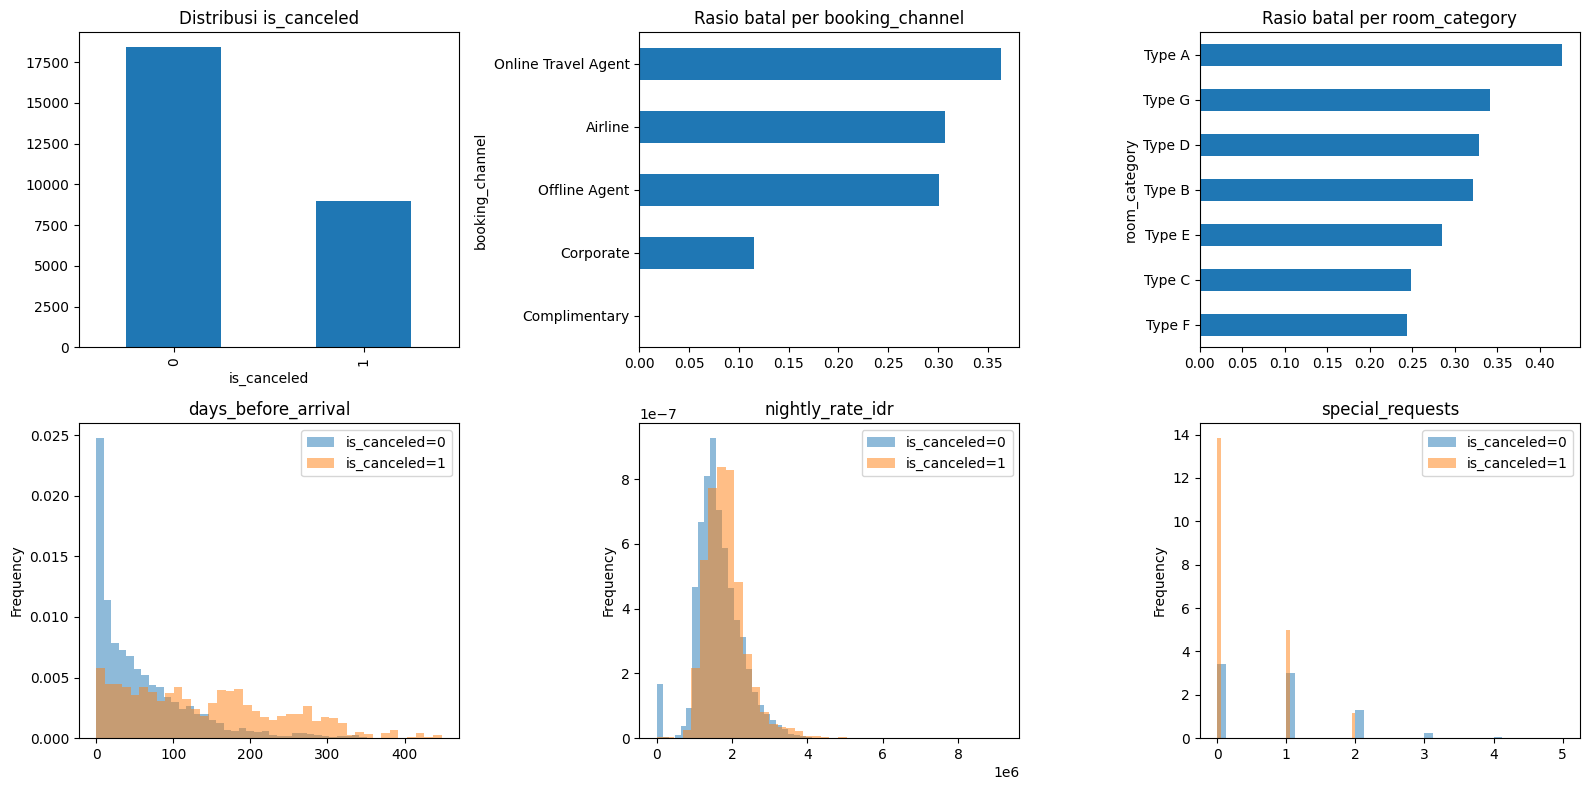

,korelasi_dengan_target
special_requests,-0.258
is_returning_guest,-0.107
needs_parking,-0.086
prior_completed_bookings,-0.059
prior_cancellations,-0.035
arrival_month,-0.016
arrival_day,0.020
num_children,0.031
weekend_nights,0.061
num_adults,0.088


,count,mean
special_requests,,
0.0,12730,0.432
1.0,8334,0.238
2.0,3246,0.143
3.0,496,0.000
4.0,60,0.000
5.0,7,0.000


,count,mean
booking_channel,,
Airline,88,0.307
Complimentary,301,0.000
Corporate,1513,0.115
Offline Agent,7960,0.302
Online Travel Agent,17511,0.364


,count,mean
arrival_year,,
2023,4924,0.147
2024,22449,0.367


In [7]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
train_df[TARGET].value_counts().sort_index().plot.bar(ax=axes[0, 0], title='Distribusi is_canceled')
for ax, col in zip(axes[0, 1:], ['booking_channel', 'room_category']):
    train_df.groupby(col)[TARGET].mean().sort_values().plot.barh(ax=ax, title=f'Rasio batal per {col}')
for ax, col in zip(axes[1], ['days_before_arrival', 'nightly_rate_idr', 'special_requests']):
    for label, part in train_df.groupby(TARGET):
        part[col].dropna().plot.hist(ax=ax, bins=40, alpha=0.5, density=True, label=f'{TARGET}={label}')
    ax.set_title(col)
    ax.legend()
plt.tight_layout()
plt.show()

num_cols = train_df.select_dtypes('number').columns.drop(TARGET)
display(train_df[num_cols].corrwith(train_df[TARGET]).sort_values().to_frame('korelasi_dengan_target').round(3))
display(train_df.groupby('special_requests')[TARGET].agg(['count', 'mean']).round(3))
for col in ['booking_channel', 'arrival_year']:
    display(train_df.groupby(col)[TARGET].agg(['count', 'mean']).round(3))

**Insights.** Fitur yang paling berkorelasi dengan pembatalan adalah `days_before_arrival` (0,440). Rasio batal naik dari 9,6 persen untuk pemesanan 7 hari sebelum kedatangan menjadi 73,6 persen untuk pemesanan lebih dari 180 hari sebelumnya. `special_requests` berkorelasi negatif (-0,258): rasio batal 43,2 persen pada pemesanan tanpa permintaan khusus, lalu turun menjadi 23,8 persen pada satu permintaan, dan tidak ada pembatalan sama sekali pada pemesanan dengan tiga permintaan atau lebih. Kanal Online Travel Agent memiliki rasio batal tertinggi (36,4 persen), sedangkan pemesanan Complimentary tidak pernah dibatalkan. Rasio batal kedatangan 2024 (36,7 persen) juga jauh lebih tinggi daripada 2023 (14,7 persen), sehingga informasi waktu kedatangan perlu dipertahankan sebagai fitur.

## Verify Data Quality

This part covers completeness, consistency, and the validity of values.

In [8]:
arrival_date = pd.to_datetime(
    dict(year=train_df['arrival_year'], month=train_df['arrival_month'], day=train_df['arrival_day']),
    errors='coerce',
)
total_nights = train_df['weekend_nights'] + train_df['weekday_nights']
quality_df = pd.Series({
    'baris duplikat (tanpa id)': int(train_df.drop(columns='id').duplicated().sum()),
    'id duplikat': int(train_df['id'].duplicated().sum()),
    'num_adults = 0 dan tanpa anak': int(((train_df['num_adults'] == 0) & (train_df['num_children'].fillna(0) == 0)).sum()),
    'nightly_rate_idr = 0': int((train_df['nightly_rate_idr'] == 0).sum()),
    'nightly_rate_idr < 0': int((train_df['nightly_rate_idr'] < 0).sum()),
    'total malam = 0': int((total_nights == 0).sum()),
    'tanggal kedatangan tidak valid': int(arrival_date.isna().sum()),
    'num_children > 4': int((train_df['num_children'] > 4).sum()),
}, name='jumlah').to_frame()
display(quality_df)

for col in CAT_COLS:
    train_values = set(train_df[col].dropna())
    print(f'{col}: {sorted(train_values)} | hanya di test: {sorted(set(test_df[col].dropna()) - train_values)}')

,jumlah
baris duplikat (tanpa id),64
id duplikat,0
num_adults = 0 dan tanpa anak,1
nightly_rate_idr = 0,413
nightly_rate_idr < 0,0
total malam = 0,64
tanggal kedatangan tidak valid,0
num_children > 4,3


meal_package: ['Breakfast', 'Full Board', 'Half Board', 'Room Only'] | hanya di test: []
room_category: ['Type A', 'Type B', 'Type C', 'Type D', 'Type E', 'Type F', 'Type G'] | hanya di test: []
booking_channel: ['Airline', 'Complimentary', 'Corporate', 'Offline Agent', 'Online Travel Agent'] | hanya di test: []


**Insights.** Tidak ada `id` ganda, tetapi terdapat 64 baris yang identik pada seluruh fitur dan label. Nilai yang tidak wajar jumlahnya kecil: satu pemesanan tanpa tamu dewasa maupun anak, 413 pemesanan dengan tarif nol, 64 pemesanan dengan total malam nol, dan tiga pemesanan dengan lebih dari empat anak. Seluruh tanggal kedatangan valid. Kategori pada data uji juga sudah muncul semua di data latih, sehingga *encoding* tidak menemui kategori baru pada data uji.

---

# Training and Validation Split <a name="4"></a>

---

The split comes before data preparation so that validation data stays unseen. Only `train.csv` is split, and `test.csv` serves the Kaggle submission alone.

In [9]:
train_set, val_set = train_test_split(
    train_df, test_size=0.2, stratify=train_df[TARGET], random_state=CFG.SEED
)
train_set, val_set = train_set.reset_index(drop=True), val_set.reset_index(drop=True)

print(f'train_set: {train_set.shape} | rasio batal {train_set[TARGET].mean():.4f}')
print(f'val_set  : {val_set.shape} | rasio batal {val_set[TARGET].mean():.4f}')

train_set: (21898, 19) | rasio batal 0.3277
val_set  : (5475, 19) | rasio batal 0.3277


**Insights.** Pembagian 80:20 terstratifikasi menghasilkan rasio batal yang sama persis (0,3277) pada kedua bagian. Semua model memakai `train_set` dan `val_set` yang sama, jadi hasil validasinya bisa dibandingkan langsung.

---

# Data Preparation <a name="5"></a>

---

Each process below applies where the data calls for it, and the Insights block under it records the reason for the decision.

Preparation steps may use `sklearn`. Every statistic comes from the training split only, then transforms the other sets.

## Select Data

Selection decides which records and attributes stay in the analysis.

In [10]:
train_ids, X_train_raw, y_train = DataPreprocessor.extract_ids_and_target(train_set)
_, X_val_raw, y_val = DataPreprocessor.extract_ids_and_target(val_set)
test_ids, X_test_raw, _ = DataPreprocessor.extract_ids_and_target(test_df)

print('Fitur yang dipakai:', list(X_train_raw.columns))
print(f'X_train_raw {X_train_raw.shape} | X_val_raw {X_val_raw.shape} | X_test_raw {X_test_raw.shape}')

Fitur yang dipakai: ['num_adults', 'num_children', 'weekend_nights', 'weekday_nights', 'meal_package', 'needs_parking', 'room_category', 'days_before_arrival', 'arrival_year', 'arrival_month', 'arrival_day', 'booking_channel', 'is_returning_guest', 'prior_cancellations', 'prior_completed_bookings', 'nightly_rate_idr', 'special_requests']
X_train_raw (21898, 17) | X_val_raw (5475, 17) | X_test_raw (6844, 17)


**Insights.** Kolom `id` dikeluarkan karena hanya berfungsi sebagai pengenal, dan target dipisahkan menjadi `y`. Ketujuh belas fitur lainnya dipertahankan pada tahap ini. Seleksi fitur yang lebih ketat dilakukan per model di dalam *pipeline*, misalnya *mutual information* 35 fitur pada SVM dan pembobotan fitur pada KNN, karena kebutuhan setiap algoritma berbeda.

## Clean Data

Cleaning raises data quality to the level the chosen models need.

### Missing Values

This part covers missing values, if any.

In [11]:
missing_df = pd.DataFrame({
    'train_set': X_train_raw.isna().sum(),
    'val_set': X_val_raw.isna().sum(),
    'test': X_test_raw.isna().sum(),
})
missing_df = missing_df[missing_df.sum(axis=1) > 0]
missing_df['rasio_batal_jika_kosong'] = [y_train[X_train_raw[c].isna().to_numpy()].mean() for c in missing_df.index]
missing_df['rasio_batal_jika_terisi'] = [y_train[X_train_raw[c].notna().to_numpy()].mean() for c in missing_df.index]
display(missing_df.round(3))

train_clean = DataPreprocessor.clean_training_dataframe(train_set, target_col=TARGET)
_, X_train_clean, y_train_clean = DataPreprocessor.extract_ids_and_target(train_clean)
prep_demo = DataPreprocessor(random_state=CFG.SEED)
X_train_demo = prep_demo.fit_transform(X_train_clean, y_train_clean, return_dataframe=True)

display(pd.Series({c: v for c, v in prep_demo.num_impute_values_.items() if c in X_train_clean.columns}, name='nilai_imputasi_median').to_frame())
display(pd.Series(prep_demo.cat_impute_values_, name='nilai_imputasi_modus').to_frame())
print('Jumlah median grup nightly_rate_idr (room_category x booking_channel):', len(prep_demo.rate_group_medians_))
print('NaN tersisa setelah transformasi:', int(X_train_demo.isna().sum().sum()))

,train_set,val_set,test,rasio_batal_jika_kosong,rasio_batal_jika_terisi
num_adults,636,173,180,0.351,0.327
num_children,2426,609,747,0.331,0.327
meal_package,1403,357,442,0.327,0.328
needs_parking,885,197,247,0.298,0.329
room_category,810,192,242,0.354,0.327
days_before_arrival,877,246,290,0.310,0.328
nightly_rate_idr,1622,416,540,0.305,0.329
special_requests,2015,485,593,0.407,0.320


,nilai_imputasi_median
num_adults,2.0
num_children,0.0
weekend_nights,1.0
weekday_nights,2.0
needs_parking,0.0
days_before_arrival,57.0
arrival_year,2024.0
arrival_month,8.0
arrival_day,16.0
is_returning_guest,0.0


,nilai_imputasi_modus
meal_package,Breakfast
room_category,Type B
booking_channel,Online Travel Agent


Jumlah median grup nightly_rate_idr (room_category x booking_channel): 25
NaN tersisa setelah transformasi: 0


**Insights.** Nilai kosong ternyata tidak acak terhadap target. Rasio batal pemesanan dengan `special_requests` kosong mencapai 40,7 persen, jauh di atas 32,0 persen pada pemesanan yang terisi. Karena itu `DataPreprocessor` menambahkan kolom indikator `<kolom>_is_missing` sebelum imputasi, sehingga informasi tersebut tidak hilang. Fitur numerik diimputasi dengan median dan fitur kategorikal dengan modus. Khusus `nightly_rate_idr`, imputasinya memakai median per kombinasi `room_category` dan `booking_channel` (25 grup), karena tarif sangat bergantung pada tipe kamar. Seluruh nilai imputasi dipelajari dari `train_set`, dan setelah transformasi tidak ada lagi nilai kosong.

### Duplicates

This part covers repeated records.

In [12]:
feature_cols = [c for c in train_set.columns if c not in ('id', TARGET)]
dup_full = train_set.drop(columns='id').duplicated(keep='first')
dup_features = train_set.duplicated(subset=feature_cols, keep=False)
dup_with_label = train_set.duplicated(subset=feature_cols + [TARGET], keep=False)

print('Baris duplikat di train_set (tanpa id):', int(dup_full.sum()))
print('Baris yang fiturnya kembar tetapi labelnya berbeda:', int((dup_features & ~dup_with_label).sum()))
print(f'Ukuran train_set: {len(train_set)} -> setelah dibersihkan: {len(train_clean)}')

Baris duplikat di train_set (tanpa id): 40
Baris yang fiturnya kembar tetapi labelnya berbeda: 2
Ukuran train_set: 21898 -> setelah dibersihkan: 21858


**Insights.** `train_set` berisi 40 baris duplikat, dan 2 baris di antaranya memiliki fitur yang kembar tetapi labelnya berbeda. Duplikat hanya dibuang dari data latih (21.898 menjadi 21.858 baris) agar pola yang sama tidak terhitung dua kali. `val_set` dan data uji tidak diubah, karena keduanya harus mencerminkan data yang akan diprediksi.

### Outliers

This part covers values far from the rest of the data.

In [13]:
num_cols_raw = X_train_clean.select_dtypes('number').columns
q1 = X_train_clean[num_cols_raw].quantile(0.25)
q3 = X_train_clean[num_cols_raw].quantile(0.75)
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outlier_df = pd.DataFrame({
    'batas_bawah_iqr': lower,
    'batas_atas_iqr': upper,
    'jumlah_di_luar_batas': ((X_train_clean[num_cols_raw] < lower) | (X_train_clean[num_cols_raw] > upper)).sum(),
    'nilai_maksimum': X_train_clean[num_cols_raw].max(),
})
display(outlier_df[outlier_df['jumlah_di_luar_batas'] > 0])

print(f'num_children > {prep_demo.max_children_clip:g} (di-clip):', int((X_train_clean['num_children'] > prep_demo.max_children_clip).sum()))
print('num_children maksimum setelah transformasi (skala asli):', X_train_clean['num_children'].clip(upper=prep_demo.max_children_clip).max())

,batas_bawah_iqr,batas_atas_iqr,jumlah_di_luar_batas,nilai_maksimum
num_adults,2.0,2.0,5916,4.0
num_children,0.0,0.0,1613,10.0
weekend_nights,-3.0,5.0,13,7.0
weekday_nights,-2.0,6.0,201,17.0
needs_parking,0.0,0.0,644,1.0
days_before_arrival,-145.0,287.0,750,448.0
arrival_year,2024.0,2024.0,3941,2024.0
is_returning_guest,0.0,0.0,545,1.0
prior_cancellations,0.0,0.0,183,13.0
prior_completed_bookings,0.0,0.0,477,58.0


num_children > 4 (di-clip): 3
num_children maksimum setelah transformasi (skala asli): 4.0


**Insights.** Aturan IQR menandai banyak nilai, tetapi sebagian besar bukan kesalahan data. Distribusi `num_adults`, `needs_parking`, dan riwayat pemesanan sangat terpusat sehingga rentang IQR-nya nol, dan setiap nilai lain langsung dianggap pencilan. Nilai ekstrem seperti `days_before_arrival` 448 hari atau tarif Rp9.165.000 masih masuk akal untuk penginapan, dan nilai itu justru membawa sinyal pembatalan. Karena itu pencilan dibiarkan, kecuali `num_children` yang di-*clip* pada 4 (tiga baris) karena nilai 10 anak dalam satu kamar tidak wajar. Model yang peka terhadap skala ditangani dengan *standardization* pada tahap berikutnya.

### Data Errors

This part covers wrong types, inconsistent labels, and impossible values.

In [14]:
error_df = pd.Series({
    'num_adults = 0 tanpa anak (diubah ke NaN)': int(((X_train_raw['num_adults'] == 0) & (X_train_raw['num_children'].fillna(0) == 0)).sum()),
    'nightly_rate_idr < 0 (diubah ke NaN)': int((X_train_raw['nightly_rate_idr'] < 0).sum()),
    'nightly_rate_idr = 0 (diberi flag is_zero_rate)': int((X_train_raw['nightly_rate_idr'] == 0).sum()),
    'total malam = 0 (diberi flag is_zero_nights)': int(((X_train_raw['weekend_nights'] + X_train_raw['weekday_nights']) == 0).sum()),
}, name='jumlah_di_train_set').to_frame()
display(error_df)

remaining = ((X_train_clean['num_adults'] == 0) & (X_train_clean['num_children'].fillna(0) == 0)).sum()
print('num_adults = 0 tanpa anak setelah clean_training_dataframe:', int(remaining))
print('Rasio batal saat nightly_rate_idr = 0:', round(float(y_train[(X_train_raw['nightly_rate_idr'] == 0).to_numpy()].mean()), 3))
print('Flag anomali di matriks fitur:', [c for c in X_train_demo.columns if c.startswith('is_zero_')])

,jumlah_di_train_set
num_adults = 0 tanpa anak (diubah ke NaN),0
nightly_rate_idr < 0 (diubah ke NaN),0
nightly_rate_idr = 0 (diberi flag is_zero_rate),324
total malam = 0 (diberi flag is_zero_nights),49


num_adults = 0 tanpa anak setelah clean_training_dataframe: 0
Rasio batal saat nightly_rate_idr = 0: 0.006
Flag anomali di matriks fitur: ['is_zero_guests', 'is_zero_nights', 'is_zero_rate']


**Insights.** Pemesanan tanpa tamu sama sekali dan tarif negatif dianggap kesalahan, sehingga nilainya diubah menjadi kosong lalu diimputasi. Tarif nol tidak dianggap salah. Pada `train_set` terdapat 324 pemesanan bertarif nol dengan rasio batal hanya 0,6 persen, dan pada seluruh data latih 267 dari 413 pemesanan bertarif nol berasal dari kanal Complimentary. Nilai itu dipertahankan dan diberi *flag* `is_zero_rate`. Total malam nol (49 baris) juga dipertahankan dengan *flag* `is_zero_nights`, karena rasio batalnya hanya 3,1 persen pada seluruh data latih dan polanya berbeda dari pemesanan biasa.

## Construct Data

Construction derives attributes and transforms values for modeling.

### Attribute Construction

<!-- rubric v3: derived columns, rate_per_guest_night -->

This part covers new attributes derived from existing ones.

In [15]:
onehot_cols = [c for c in X_train_demo.columns if not c.endswith('_is_missing') and any(c.startswith(f'{k}_') for k in CAT_COLS)]
missing_indicator_cols = [c for c in X_train_demo.columns if c.endswith('_is_missing')]
constructed_cols = [c for c in X_train_demo.columns if c not in X_train_clean.columns and c not in onehot_cols and c not in missing_indicator_cols]

print(f'Kolom asli: {X_train_clean.shape[1]} | kolom setelah transformasi: {X_train_demo.shape[1]}')
print(f'One-hot: {len(onehot_cols)} | indikator missing: {len(missing_indicator_cols)} | atribut turunan: {len(constructed_cols)}')
display(X_train_demo[constructed_cols].describe().T[['mean', 'std', 'min', 'max']].round(3))

Kolom asli: 17 | kolom setelah transformasi: 59
One-hot: 14 | indikator missing: 8 | atribut turunan: 23


,mean,std,min,max
total_missing_cols,0.0,1.0,-0.709,6.572
is_zero_guests,0.0,0.0,0.000,0.000
is_zero_nights,0.0,1.0,-0.047,21.097
is_zero_rate,0.0,1.0,-0.122,8.204
total_nights,0.0,1.0,-1.673,11.635
weekend_ratio,0.0,1.0,-0.948,2.470
total_guests,0.0,1.0,-1.496,6.326
has_children,-0.0,1.0,-0.282,3.543
total_spend_idr,-0.0,1.0,-1.455,14.121
rate_per_adult,0.0,1.0,-2.332,8.880


**Insights.** Tujuh belas kolom asli berkembang menjadi 60 kolom: 14 kolom *one-hot*, 8 indikator nilai kosong, dan 24 atribut turunan. Atribut turunan disusun dari pengetahuan domain penginapan, misalnya total malam, total biaya, tarif per tamu per malam, rasio pembatalan sebelumnya, hari kedatangan, dan bulan kedatangan dalam bentuk siklik (`month_sin`, `month_cos`). `lead_to_stay_ratio` membagi `days_before_arrival` dengan lama menginap, karena jarak pemesanan adalah sinyal terkuat pada tahap eksplorasi. `is_zero_guests` bernilai konstan pada `train_set`, karena satu-satunya baris tanpa tamu berada di `val_set`. Konfigurasi Logistic Regression dan Naive Bayes menambahkan interaksi komposit di atas atribut ini.

### Feature Scaling

This part covers normalization to the range 0 to 1 and standardization.

In [16]:
scaled_cols = list(prep_demo.scaler_params_)
display(X_train_demo[scaled_cols].agg(['mean', 'std']).T.round(3).head(10))

prep_minmax = DataPreprocessor(scaling_method='minmax', random_state=CFG.SEED)
X_train_minmax = prep_minmax.fit_transform(X_train_clean, y_train_clean, return_dataframe=True)
display(X_train_minmax[scaled_cols].agg(['min', 'max']).T.round(3).head(10))

X_val_minmax = prep_minmax.transform(X_val_raw, return_dataframe=True)
print('Rentang min-max pada val_set:', round(float(X_val_minmax[scaled_cols].min().min()), 3), 'sampai', round(float(X_val_minmax[scaled_cols].max().max()), 3))

,mean,std
num_adults,0.0,1.0
num_children,-0.0,1.0
weekend_nights,-0.0,1.0
weekday_nights,0.0,1.0
needs_parking,-0.0,1.0
days_before_arrival,-0.0,1.0
arrival_year,0.0,1.0
arrival_month,0.0,1.0
arrival_day,-0.0,1.0
is_returning_guest,0.0,1.0


,min,max
num_adults,0.0,1.0
num_children,0.0,1.0
weekend_nights,0.0,1.0
weekday_nights,0.0,1.0
needs_parking,0.0,1.0
days_before_arrival,0.0,1.0
arrival_year,0.0,1.0
arrival_month,0.0,1.0
arrival_day,0.0,1.0
is_returning_guest,0.0,1.0


Rentang min-max pada val_set: 0.0 sampai 1.11


**Insights.** *Standardization* menghasilkan rata-rata 0 dan simpangan baku 1 pada `train_set`, sedangkan normalisasi *min-max* memetakan `train_set` ke rentang 0 sampai 1. Pada `val_set`, hasil *min-max* dapat melewati 1 (sampai 1,11), karena batasnya dipelajari dari data latih saja. *Standardization* dipakai untuk KNN, SVM, dan Logistic Regression baseline, karena ketiganya bergantung pada jarak atau besar bobot. Bagian SVM juga membandingkan keduanya (varian B pada eksperimen *preprocessing*). DTL dan Naive Bayes tidak memakai *scaling*, karena keputusan pada kedua model itu tidak dipengaruhi skala fitur.

### Encoding

This part covers the numeric representation of categorical attributes.

In [17]:
display(pd.Series({c: list(v) for c, v in prep_demo.onehot_categories_.items()}, name='kategori_one_hot').to_frame())

prep_ordinal = DataPreprocessor(encoding_method='ordinal', scaling_method='none', random_state=CFG.SEED)
prep_ordinal.fit(X_train_clean, y_train_clean)
display(pd.Series({c: dict(v) for c, v in prep_ordinal.ordinal_mappings_.items()}, name='pemetaan_ordinal').to_frame())

unseen_check = X_val_raw.head(3).copy()
unseen_check['room_category'] = 'Type Z'
unseen_out = prep_demo.transform(unseen_check, return_dataframe=True)
room_onehot = [c for c in unseen_out.columns if c.startswith('room_category_') and not c.endswith('_is_missing')]
print('Kolom one-hot yang aktif untuk kategori tak dikenal "Type Z":', list(unseen_out.loc[0, room_onehot][unseen_out.loc[0, room_onehot] > 0].index))
print('Kategori langka yang tidak mendapat kolom one-hot sendiri:', {c: sorted(set(X_train_clean[c].dropna()) - set(v)) for c, v in prep_demo.onehot_categories_.items()})

,kategori_one_hot
meal_package,"[Breakfast, Half Board, Room Only]"
room_category,"[Type A, Type B, Type C, Type D, Type F, Type G]"
booking_channel,"[Airline, Complimentary, Corporate, Offline Ag..."


,pemetaan_ordinal
meal_package,"{'Breakfast': 0, 'Half Board': 1, 'Room Only': 2}"
room_category,"{'Type A': 0, 'Type B': 1, 'Type C': 2, 'Type ..."
booking_channel,"{'Airline': 0, 'Complimentary': 1, 'Corporate'..."


Kolom one-hot yang aktif untuk kategori tak dikenal "Type Z": ['room_category_Type_B']


Kategori langka yang tidak mendapat kolom one-hot sendiri: {'meal_package': ['Full Board'], 'room_category': ['Type E'], 'booking_channel': []}


**Insights.** *One-hot encoding* dipakai untuk model berbasis jarak dan model linear, agar tidak tercipta urutan semu di antara kategori. Kategori yang muncul kurang dari 10 kali di data latih (Full Board dan Type E) tidak mendapat kolom sendiri. Kategori langka dan kategori yang belum pernah dilihat dipetakan ke modus, sehingga transformasi tetap berjalan pada data baru. Uji dengan kategori fiktif "Type Z" menunjukkan pemetaan ke `room_category_Type_B`. *Ordinal encoding* dipakai pada konfigurasi Logistic Regression teroptimasi dan Naive Bayes, karena keduanya membentuk fitur turunan dari kode kategori. DTL menerima kategori secara langsung.

### Dimensionality Reduction

This part covers fewer dimensions that keep the meaning of the data.

In [18]:
def evaluate_lr_baseline(prep: DataPreprocessor, X_tr: pd.DataFrame, y_tr: np.ndarray, X_ev: pd.DataFrame, y_ev: np.ndarray) -> dict:
    A = prep.fit_transform(X_tr, y_tr)
    B = prep.transform(X_ev)
    model = LogisticRegression(penalty='l2', C=1.0, optimizer='lbfgs', max_iter=200, random_state=CFG.SEED).fit(A, y_tr)
    m = compute_classification_metrics(y_ev, model.predict(B), model.predict_proba(B)[:, 1])
    return {'n_fitur': A.shape[1], 'accuracy': m['accuracy'], 'f1_macro': m['f1_macro'], 'roc_auc': m['roc_auc']}


pca_rows = []
for label, extra in [
    ('tanpa PCA', {}),
    ('PCA 95% varians', {'use_pca': True, 'pca_n_components': 0.95}),
    ('PCA 80% varians', {'use_pca': True, 'pca_n_components': 0.80}),
]:
    pca_rows.append({'konfigurasi': label, **evaluate_lr_baseline(DataPreprocessor(random_state=CFG.SEED, **extra), X_train_clean, y_train_clean, X_val_raw, y_val)})
display(pd.DataFrame(pca_rows).round(4))

,konfigurasi,n_fitur,accuracy,f1_macro,roc_auc
0,tanpa PCA,59,0.8002,0.7627,0.8597
1,PCA 95% varians,30,0.7995,0.7597,0.8566
2,PCA 80% varians,21,0.7823,0.7302,0.8319


**Insights.** PCA diuji dengan Logistic Regression (L2, L-BFGS) pada `val_set`. Reduksi ke 30 komponen (95 persen varians) menurunkan *macro F1* dari 0,7623 menjadi 0,7605, dan reduksi ke 21 komponen (80 persen varians) menurunkannya menjadi 0,7307. Jumlah fitur awal hanya 60, sehingga biaya komputasi tidak menjadi masalah, sementara PCA membuang informasi yang dipakai model. Karena itu PCA tidak dipakai pada model final. Bagian SVM sampai pada kesimpulan yang sama (varian C), dan PCA hanya dipakai untuk visualisasi bidang pemisah 2D.

## Class Balance

This part covers the proportion of each class in the training data.

In [19]:
display(pd.DataFrame({
    'train_set': train_set[TARGET].value_counts(normalize=True),
    'val_set': val_set[TARGET].value_counts(normalize=True),
}).round(4))

X_train_np = X_train_demo.to_numpy(dtype=np.float64)
X_val_np = prep_demo.transform(X_val_raw)
balance_rows = []
for method in ['none', 'random_oversample', 'random_undersample', 'smote']:
    A, ya = (X_train_np, y_train_clean) if method == 'none' else prep_demo.resample(X_train_np, y_train_clean, method=method)
    model = LogisticRegression(penalty='l2', C=1.0, optimizer='lbfgs', max_iter=200, random_state=CFG.SEED).fit(A, ya)
    m = compute_classification_metrics(y_val, model.predict(X_val_np))
    balance_rows.append({
        'metode': method, 'n_latih': len(ya), 'rasio_positif_latih': round(float(np.mean(ya)), 4),
        'accuracy': m['accuracy'], 'f1_macro': m['f1_macro'],
        'precision_batal': m['precision_binary'], 'recall_batal': m['recall_binary'],
    })
display(pd.DataFrame(balance_rows).round(4))

,train_set,val_set
is_canceled,,
0,0.6723,0.6723
1,0.3277,0.3277


,metode,n_latih,rasio_positif_latih,accuracy,f1_macro,precision_batal,recall_batal
0,none,21858,0.3277,0.8002,0.7627,0.7324,0.6148
1,random_oversample,29392,0.5000,0.7763,0.7579,0.6308,0.7648
2,random_undersample,14324,0.5000,0.7750,0.7567,0.6289,0.7642
3,smote,29392,0.5000,0.7750,0.7565,0.6294,0.7620


**Insights.** Perbandingan kelas 67:33 termasuk ketidakseimbangan sedang. Ketiga metode *resampling* menaikkan *recall* kelas batal dari 0,615 menjadi sekitar 0,76, tetapi *precision* turun dari 0,731 menjadi sekitar 0,63. Akibatnya *macro F1* justru turun dari 0,7623 menjadi 0,7566 sampai 0,7573. *Resampling* tidak dipakai, dan pergeseran keseimbangan antara *precision* dan *recall* diatur lewat *threshold* keputusan, karena cara ini tidak mengubah distribusi data latih. *Resampling*, jika dipakai, hanya diterapkan pada data latih.

## Format Data

Formatting produces the structure the models read, such as a numeric matrix.

In [20]:
X_test_np = prep_demo.transform(X_test_raw)
format_df = pd.DataFrame([
    {'set': name, 'shape': X.shape, 'dtype': str(X.dtype), 'ada_nan': bool(np.isnan(X).any()), 'semua_finite': bool(np.isfinite(X).all())}
    for name, X in [('train', X_train_np), ('val', X_val_np), ('test', X_test_np)]
])
display(format_df)
print('Urutan kolom train dan test sama:', list(prep_demo.transform(X_test_raw, return_dataframe=True).columns) == list(X_train_demo.columns))

,set,shape,dtype,ada_nan,semua_finite
0,train,"(21858, 59)",float64,False,True
1,val,"(5475, 59)",float64,False,True
2,test,"(6844, 59)",float64,False,True


Urutan kolom train dan test sama: True


**Insights.** Ketiga himpunan sudah berupa matriks `float64` tanpa nilai kosong maupun nilai tak hingga, dengan urutan kolom yang sama. Format ini dapat langsung dibaca oleh model *from scratch* yang hanya memakai NumPy.

---

# Preparation Pipeline <a name="6"></a>

---

<!-- rubric v3: fitted steps, fitted_prep_steps -->

The pipeline combines the preparation steps so they run in one consistent order.

In [21]:
def build_feature_matrices(prep: DataPreprocessor, train_part: pd.DataFrame, other_parts: list, return_dataframe: bool = False):
    train_clean_part = DataPreprocessor.clean_training_dataframe(train_part, target_col=TARGET)
    _, X_tr, y_tr = DataPreprocessor.extract_ids_and_target(train_clean_part)
    A = prep.fit_transform(X_tr, y_tr, return_dataframe=return_dataframe)
    others = [prep.transform(DataPreprocessor.extract_ids_and_target(p)[1], return_dataframe=return_dataframe) for p in other_parts]
    return prep, A, y_tr, others


PIPELINE_CONFIGS = {
    'KNN': knn_exp.make_preprocessor(),
    'Decision Tree (CART)': DataPreprocessor(mode='dtl_ready', random_state=CFG.SEED),
    'Logistic Regression': lr_exp._make_optimized_preprocessor(CFG.SEED),
    'SVM': svm_exp.make_preprocessor(),
    'Naive Bayes': nb_exp._make_optimized_preprocessor(CFG.SEED),
}
PIPELINE_KEYS = [
    'mode', 'add_missing_indicators', 'add_domain_features', 'add_composite_interactions',
    'add_linear_nonlinear_features', 'encoding_method', 'scaling_method',
    'feature_selection_method', 'n_features_to_select', 'use_pca', 'imbalance_method',
]
display(pd.DataFrame({
    name: {k: getattr(p, k) if p.mode != 'dtl_ready' or k == 'mode' else '-' for k in PIPELINE_KEYS}
    for name, p in PIPELINE_CONFIGS.items()
}))

_, pipe_train, pipe_y, (pipe_val, pipe_test) = build_feature_matrices(DataPreprocessor(random_state=CFG.SEED), train_set, [val_set, test_df])
print('Pipeline default:', pipe_train.shape, pipe_val.shape, pipe_test.shape)
print('Hasil sama dengan langkah manual di atas:', np.array_equal(pipe_train, X_train_np) and np.array_equal(pipe_val, X_val_np))

,KNN,Decision Tree (CART),Logistic Regression,SVM,Naive Bayes
mode,processed_numeric,dtl_ready,processed_numeric,processed_numeric,processed_numeric
add_missing_indicators,True,-,True,True,True
add_domain_features,True,-,True,True,True
add_composite_interactions,False,-,True,False,True
add_linear_nonlinear_features,False,-,True,False,False
encoding_method,onehot,-,ordinal,onehot,ordinal
scaling_method,standard,-,none,standard,none
feature_selection_method,none,-,none,none,tan_v3
n_features_to_select,None,-,None,None,None
use_pca,False,-,False,False,False


Pipeline default: (21858, 59) (5475, 59) (6844, 59)
Hasil sama dengan langkah manual di atas: True


**Insights.** Fungsi `build_feature_matrices` menyatukan seluruh langkah di atas dalam satu urutan: *cleaning* data latih, pemisahan `id` dan target, indikator nilai kosong dan *flag* anomali, imputasi, konstruksi atribut, *encoding*, *scaling*, seleksi fitur, lalu PCA jika diaktifkan. Statistik setiap langkah dipelajari lewat `fit` pada data latih, kemudian `transform` dipakai untuk data validasi dan data uji. Hasil fungsi ini identik dengan langkah manual di atas.

Tabel konfigurasi menunjukkan bahwa semua model memakai kelas `DataPreprocessor` yang sama, dan perbedaannya hanya pada parameter. SVM memakai seleksi *mutual information* 35 fitur tanpa indikator nilai kosong. Logistic Regression menambahkan fitur interaksi dan fitur taklinear tanpa *scaling*. DTL memakai mode `dtl_ready` yang mempertahankan nilai kosong dan kategori asli, karena spesifikasi meminta DTL menangani keduanya secara langsung. Naive Bayes memakai interaksi komposit dan *ordinal encoding* tanpa *scaling*, lalu memilih 38 fitur yang dipakai untuk membangun struktur TAN.

---

# Modeling and Validation <a name="7"></a>

---

The target is `is_canceled`. The models here are implemented from scratch, with math libraries such as NumPy.

## K-Nearest Neighbors

<!-- rubric v3: pairwise distances, val_neighbor_dists -->

This part covers the nearest neighbor classifier and its validation.

Implementasi ada di `src/models/knn.py` (kelas `KNN`, hanya NumPy), dan konfigurasinya berasal dari `src/experiments/run_knn_experiment.py`.

- **Jarak.** *Manhattan distance* dihitung per *batch* 256 baris agar memori tetap terkendali. *Euclidean* dihitung lewat identitas $\lVert a-b \rVert^2 = \lVert a \rVert^2 - 2a \cdot b + \lVert b \rVert^2$.
- **Voting.** Setiap tetangga diberi bobot $1/d$ (`weights='distance'`) dengan $k = 25$, sehingga tetangga yang lebih dekat lebih berpengaruh.
- **Bobot fitur.** Setiap fitur dikalikan bobot sebelum jarak dihitung. Bobot dicari dengan `search_knn_weights.py`, dan fitur berbobot 0 dibuang.
- **Threshold.** Kelas batal diprediksi jika proporsi suara tetangga batal minimal 0,48.

In [22]:
knn_train_clean = DataPreprocessor.clean_training_dataframe(train_set, target_col=TARGET)
knn_y_tr = knn_train_clean[TARGET].to_numpy()
knn_X_tr, knn_X_val, knn_columns = knn_exp.preprocess(knn_train_clean, val_set)
knn_weights = weight_vector(knn_columns, knn_exp.FEATURE_WEIGHTS)
print(f'Matriks KNN: train {knn_X_tr.shape}, val {knn_X_val.shape} | fitur berbobot 0: {int((knn_weights == 0).sum())}')
print('Parameter:', knn_exp.KNN_PARAMS, '| threshold:', knn_exp.THRESHOLD)

knn_rows, knn_outputs = [], {}
for label, weights in [('KNN tanpa bobot fitur', None), ('KNN berbobot fitur', knn_weights)]:
    model = KNN(**knn_exp.KNN_PARAMS, feature_weights=weights)
    t0 = time.perf_counter()
    model.fit(knn_X_tr, knn_y_tr)
    t1 = time.perf_counter()
    proba = model.predict_proba(knn_X_val)[:, 1]
    t2 = time.perf_counter()
    pred = (proba >= knn_exp.THRESHOLD).astype(int)
    knn_outputs[label] = {'model': model, 'pred': pred, 'proba': proba}
    knn_rows.append({
        'model': label, 'implementation': 'from_scratch',
        **compute_classification_metrics(y_val, pred, proba),
        'fit_time_s': t1 - t0, 'predict_time_s': t2 - t1,
    })

knn_model = knn_outputs['KNN berbobot fitur']['model']
knn_val_pred = knn_outputs['KNN berbobot fitur']['pred']
knn_val_proba = knn_outputs['KNN berbobot fitur']['proba']
display(summarize_models(knn_rows)[['model', 'accuracy', 'precision_binary', 'recall_binary', 'f1_macro', 'roc_auc', 'predict_time_s']].round(4))

Matriks KNN: train (21858, 61), val (5475, 61) | fitur berbobot 0: 14
Parameter: {'n_neighbors': 25, 'metric': 'manhattan', 'weights': 'distance'} | threshold: 0.48


,model,accuracy,precision_binary,recall_binary,f1_macro,roc_auc,predict_time_s
0,KNN tanpa bobot fitur,0.8385,0.8182,0.6522,0.8057,0.9028,63.2520
1,KNN berbobot fitur,0.8703,0.8140,0.7832,0.8514,0.9350,51.0222


In [23]:
knn_dist, knn_idx = knn_model.kneighbors(knn_X_val[:5])
display(pd.DataFrame({
    'label_asli': y_val[:5],
    'jarak_tetangga_terdekat': knn_dist[:, 0].round(3),
    'jarak_tetangga_ke_25': knn_dist[:, -1].round(3),
    'rasio_batal_tetangga': knn_y_tr[knn_idx].mean(axis=1).round(3),
    'prediksi': knn_val_pred[:5],
}))

,label_asli,jarak_tetangga_terdekat,jarak_tetangga_ke_25,rasio_batal_tetangga,prediksi
0,0,3.539,7.596,0.00,0
1,1,4.759,12.423,0.80,1
2,0,0.956,6.304,0.12,0
3,1,4.892,9.020,0.80,1
4,1,0.832,4.765,0.60,1


**Insights.** Pembobotan fitur menaikkan *macro F1* KNN dari 0,8041 menjadi 0,8518 dan akurasi dari 0,8371 menjadi 0,8709. Tanpa bobot, setiap fitur hasil *standardization* berkontribusi setara terhadap jarak, termasuk 14 fitur yang hampir tidak berhubungan dengan pembatalan. Bobot yang besar pada `days_before_arrival`, `special_requests`, dan tanggal kedatangan membuat tetangga terdekat dipilih berdasarkan fitur yang memang informatif. KNN tidak memiliki tahap pelatihan, sehingga biaya komputasinya muncul saat prediksi (sekitar 18 detik untuk 5.475 baris validasi).

## Decision Tree Learning

This part covers one chosen variant, which is ID3, C4.5, or CART, and its validation.

Implementasi ada di `src/models/dtl.py` (kelas `DecisionTree`, murni NumPy + pustaka standar) dan skrip eksperimen di `src/experiments/run_dtl_experiment.py`. Ringkasan desain:
- **Fitur numerik**: *binary threshold split* $x \le t$ dengan kandidat kuantil (`n_bins=64`, tervektorisasi).
- **Fitur kategorikal**: *optimal binary subset split* $x \in S$ berdasarkan pengurutan proporsi kelas positif $P(y=1 \mid x=c)$ (Breiman et al., 1984).
- **Nilai kosong (NaN)**: ditangani langsung secara internal (`null_handling='learned' / 'c45'`) tanpa imputasi luar, memakai jalur data `DataPreprocessor(mode='dtl_ready')`.
- **Bonus Optimasi (2 poin)**: *Minimal Cost-Complexity Pruning* (`ccp_alpha`, *weakest-link pruning*) berbasis *bottom-up dynamic programming* $O(N)$.
- **Bonus Visualisasi (1 poin)**: `plot_tree(top_n=3)` menampilkan percabangan teratas pohon keputusan.


In [24]:
import sys
from pathlib import Path
from IPython.display import Image, display

ROOT_DIR = Path.cwd().parent if Path.cwd().name == 'src' else Path.cwd()
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

from src.experiments.run_dtl_experiment import (
    BEST_DTL_PARAMS,
    FIGURES_DIR as DTL_FIGURES_DIR,
    MODELS_DIR as DTL_MODELS_DIR,
    SUBMISSIONS_DIR as DTL_SUBMISSIONS_DIR,
    prepare_dtl_folds,
    run_cv_tuning,
    run_sklearn_comparison,
    train_final_and_export,
)
from src.models.dtl import DecisionTree
from src.utils.model_io import load_model, save_model

dtl_clean_df, dtl_y, dtl_fold, dtl_folds = prepare_dtl_folds(train_df, n_splits=5, seed=CFG.SEED)
print(f'Train bersih (dtl_ready): {dtl_clean_df.shape} | rasio cancel: {dtl_y.mean():.4f}')

Train bersih (dtl_ready): (27309, 19) | rasio cancel: 0.3275


### Pemilihan Hyperparameter & Bonus Minimal Cost-Complexity Pruning (ccp_alpha)

In [25]:
dtl_cv_df, dtl_best_params = run_cv_tuning(dtl_folds, seed=CFG.SEED)
display(dtl_cv_df.round(4))
print('Parameter final terpilih:', dtl_best_params)

,criterion,max_depth,min_samples_leaf,min_samples_split,n_bins,ccp_alpha,cv_macroF1,cv_std,train_macroF1,gap
0,entropy,22,5,10,64,0.0001,0.8316,0.0042,0.8775,0.0459
1,entropy,22,5,10,64,0.0001,0.8307,0.0048,0.8685,0.0378
2,entropy,22,5,10,64,0.0001,0.8305,0.0043,0.8563,0.0258
3,entropy,22,8,16,64,0.0001,0.8293,0.0036,0.8568,0.0275
4,entropy,22,8,16,64,0.0001,0.8286,0.0033,0.8658,0.0372
5,entropy,22,8,16,64,0.0001,0.8282,0.0024,0.8716,0.0434
6,gini,12,5,10,64,0.0000,0.8272,0.0023,0.8698,0.0426
7,entropy,12,8,16,64,0.0000,0.8268,0.0047,0.8570,0.0302
8,entropy,12,5,10,64,0.0000,0.8261,0.0039,0.8623,0.0362
9,gini,12,8,16,64,0.0000,0.8253,0.0019,0.8642,0.0389


Parameter final terpilih: {'criterion': 'entropy', 'max_depth': 22, 'min_samples_leaf': 5, 'min_samples_split': 10, 'n_bins': 64, 'ccp_alpha': 0.0001}


### Bonus: Visualisasi Top-N Percabangan Decision Tree

Kedalaman pohon final: 21 | Jumlah daun: 250


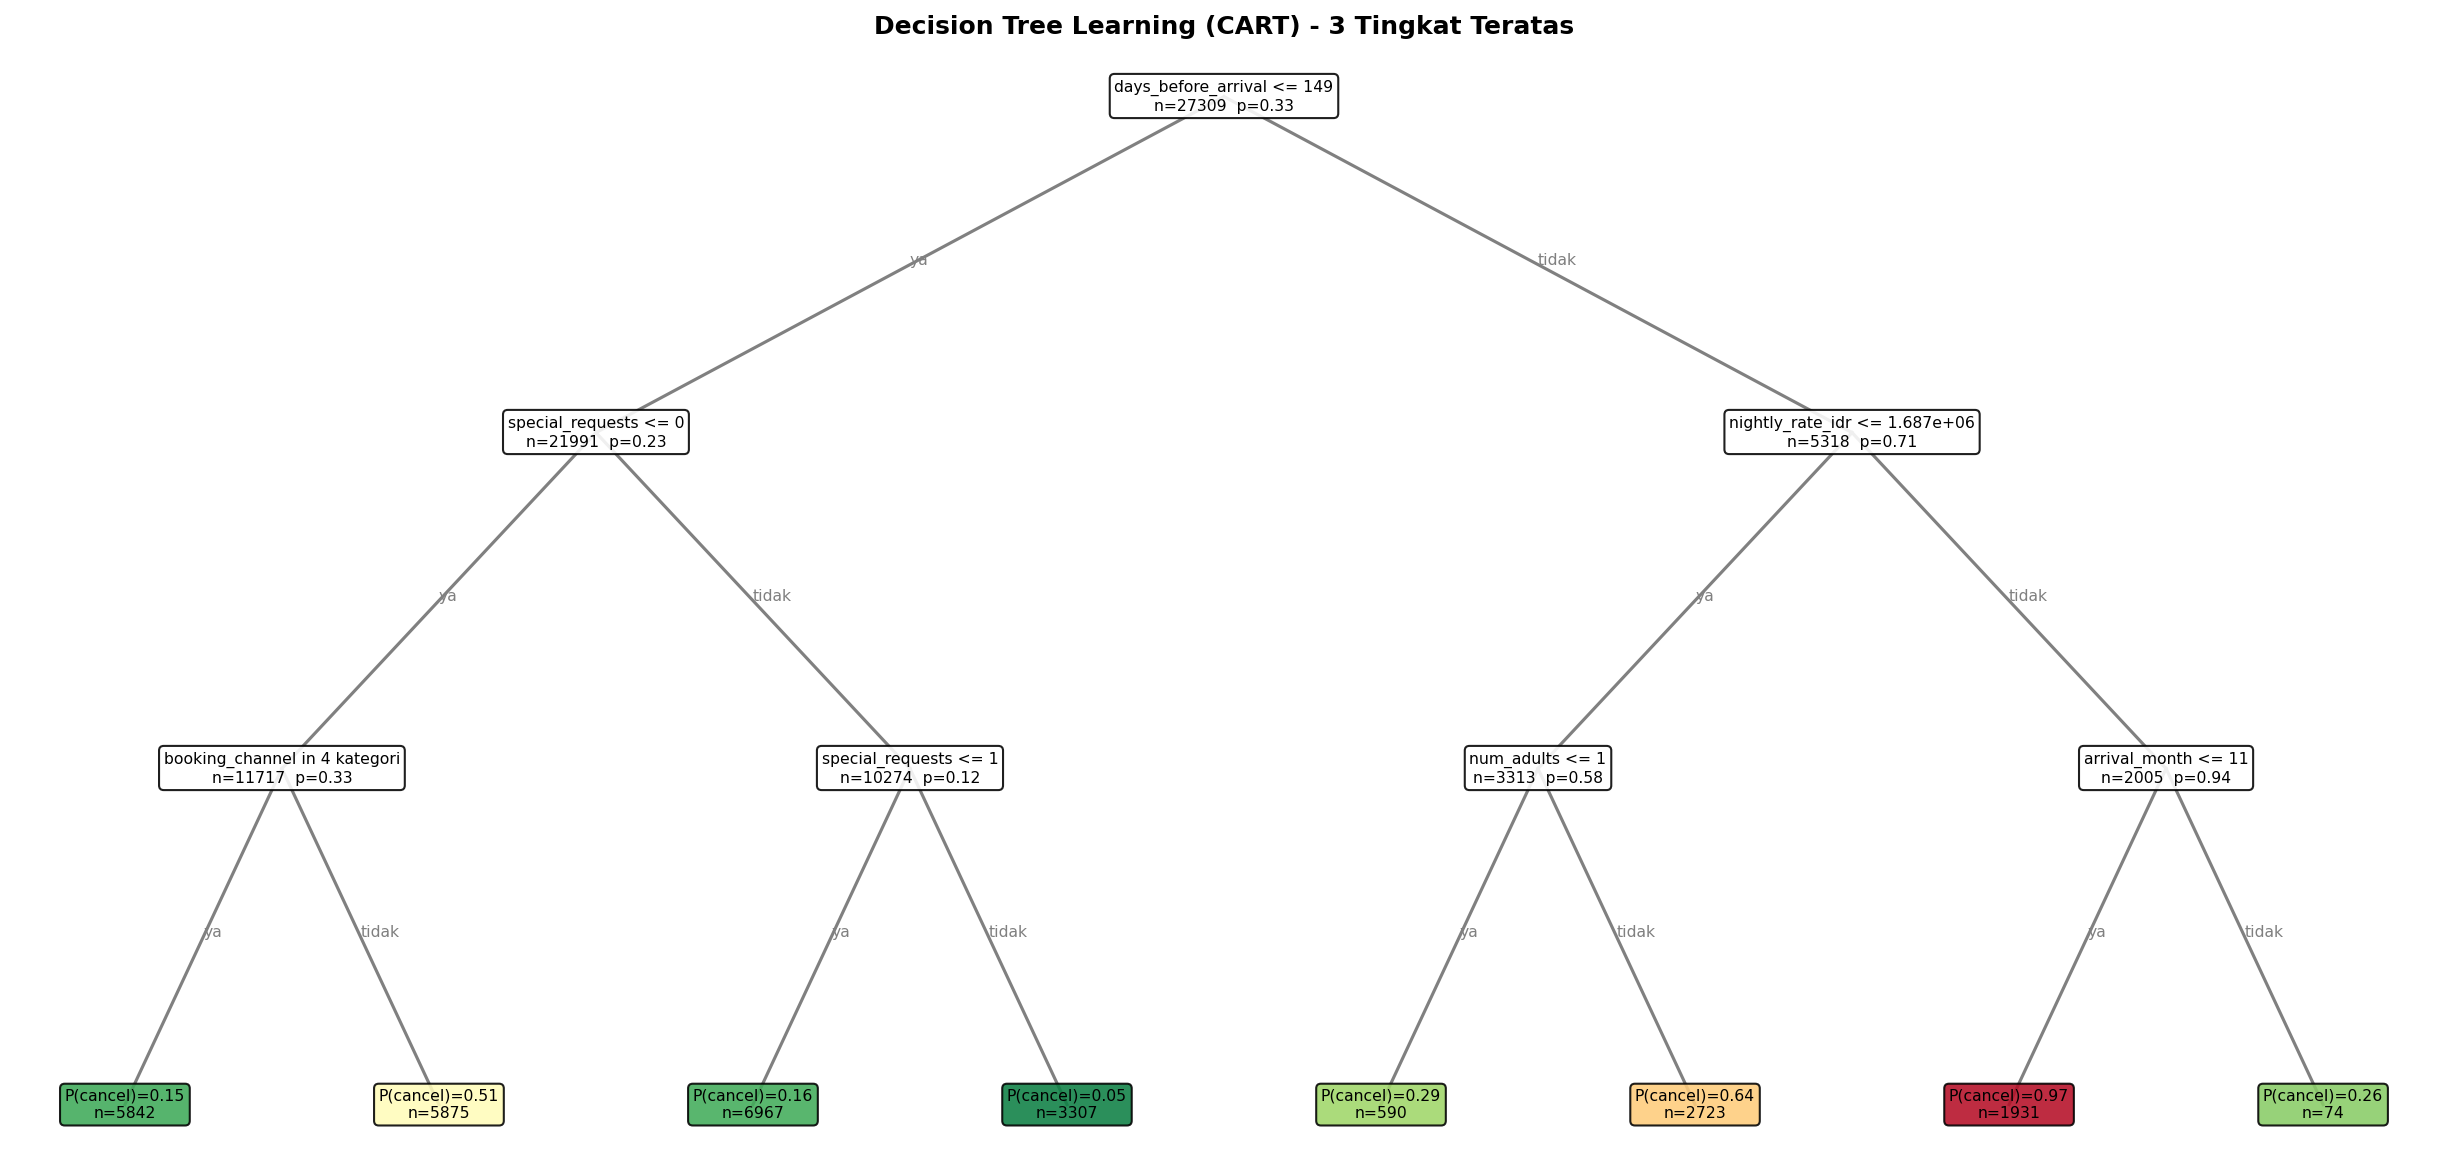

In [26]:
dtl_final_model, dtl_model_path, dtl_tree_path, dtl_sub_path = train_final_and_export(
    dtl_clean_df, test_df, dtl_best_params, seed=CFG.SEED, show_tree=False
)
print(f'Kedalaman pohon final: {dtl_final_model.get_depth()} | Jumlah daun: {dtl_final_model.count_leaves()}')
display(Image(filename=str(dtl_tree_path)))

## Logistic Regression

This part covers the model with L1, L2, and Elastic Net regularization.

Implementasi ada di `src/models/logistic_regression.py` (kelas `LogisticRegression`, hanya NumPy). Model memaksimalkan *log-likelihood* $\sum_i \left[y_i \log p_i + (1-y_i)\log(1-p_i)\right]$ dengan $p_i = \sigma(b^\top x_i)$, sesuai pendekatan *Maximum Likelihood* pada materi kuliah.

- **Regularisasi.** L1 $\lambda\lVert w\rVert_1$ (sub-gradien $\lambda\,\mathrm{sign}(w)$), L2 $\frac{\lambda}{2}\lVert w\rVert_2^2$, dan Elastic Net sebagai kombinasi keduanya dengan `l1_ratio`. Nilai $\lambda = 1/(C \cdot n)$ disamakan dengan parameter `C` pada `scikit-learn`, dan bias $b_0$ tidak diregularisasi.
- **Optimizer materi kuliah.** *Stochastic Gradient Ascent* memperbarui $b_j \leftarrow b_j + \eta\,(y_i - p_i)\,x_{ij}$ untuk setiap contoh acak (Elkan, 2014).
- **Bonus optimasi model.** Adam (Kingma & Ba, 2014) menyesuaikan *learning rate* setiap parameter dengan momen pertama dan kedua gradien. L-BFGS (Liu & Nocedal, 1989) memakai aproksimasi Hessian dari beberapa pasangan gradien terakhir (`lbfgs_memory`) dengan *Armijo backtracking line search*, sehingga konvergen dalam lebih sedikit iterasi. L-BFGS hanya dipakai untuk penalti yang terdiferensialkan (L2 dan tanpa penalti).
- **Bonus video.** `animate_loss_contour` menghasilkan animasi kontur *log-loss* beserta lintasan parameter $(\theta_0, \theta_1)$ pada masalah satu fitur. Lintasannya ilustratif, seperti dijelaskan pada subbagian video kontur di bawah.

In [27]:
LR_PENALTY_CONFIGS = {
    'none': dict(penalty='none', optimizer='lbfgs', max_iter=200),
    'l1': dict(penalty='l1', C=1.0, optimizer='adam', learning_rate=0.01, max_iter=60, batch_size=256),
    'l2': dict(penalty='l2', C=1.0, optimizer='lbfgs', max_iter=200),
    'elasticnet': dict(penalty='elasticnet', C=1.0, l1_ratio=0.5, optimizer='adam', learning_rate=0.01, max_iter=60, batch_size=256),
}

_, lr_X_tr_base, lr_y_tr, (lr_X_val_base,) = build_feature_matrices(lr_exp._make_baseline_preprocessor(CFG.SEED), train_set, [val_set])
print(f'Fitur baseline: train {lr_X_tr_base.shape}, val {lr_X_val_base.shape}')

lr_penalty_models, lr_penalty_rows = {}, []
for penalty, kwargs in LR_PENALTY_CONFIGS.items():
    model = LogisticRegression(**kwargs, random_state=CFG.SEED)
    t0 = time.perf_counter()
    model.fit(lr_X_tr_base, lr_y_tr)
    fit_t = time.perf_counter() - t0
    proba = model.predict_proba(lr_X_val_base)[:, 1]
    lr_penalty_models[penalty] = model
    lr_penalty_rows.append({
        'model': f'LogReg {penalty}', 'implementation': 'from_scratch', 'optimizer': kwargs['optimizer'],
        **compute_classification_metrics(y_val, (proba >= 0.5).astype(int), proba),
        'n_iter': model.n_iter_, 'bobot_nol': int(np.sum(np.abs(model.coef_) < 1e-6)), 'fit_time_s': fit_t,
    })
display(summarize_models(lr_penalty_rows)[['model', 'optimizer', 'accuracy', 'f1_macro', 'roc_auc', 'n_iter', 'bobot_nol', 'fit_time_s']].round(4))

Fitur baseline: train (21858, 59), val (5475, 59)


,model,optimizer,accuracy,f1_macro,roc_auc,n_iter,bobot_nol,fit_time_s
0,LogReg none,lbfgs,0.8000,0.7628,0.8597,139,1,0.2339
1,LogReg l1,adam,0.7980,0.7576,0.8592,60,1,0.8611
2,LogReg l2,lbfgs,0.8002,0.7627,0.8597,135,1,0.2248
3,LogReg elasticnet,adam,0.7978,0.7574,0.8592,60,1,0.7103


**Insights.** Pada 60 fitur baseline, keempat mode regularisasi menghasilkan *macro F1* yang hampir sama (0,7579 sampai 0,7623). Dengan 21.858 baris latih dan `C = 1`, nilai $\lambda$ sangat kecil, sehingga penalti hampir tidak mengubah bobot. L1 dan Elastic Net juga tidak menghasilkan bobot yang tepat nol, karena sub-gradien $\lambda\,\mathrm{sign}(w)$ membuat bobot berosilasi di sekitar nol. Satu-satunya bobot nol pada setiap mode berasal dari kolom `is_zero_guests` yang konstan.

,optimizer,n_iter,loss_akhir,accuracy,f1_macro,roc_auc,fit_time_s
0,Stochastic Gradient Ascent,10,0.44142,0.78064,0.74771,0.85328,4.63202
1,Adam (bonus),60,0.42759,0.79763,0.75724,0.85921,0.59045
2,L-BFGS (bonus),135,0.42608,0.80018,0.76274,0.85972,0.21221


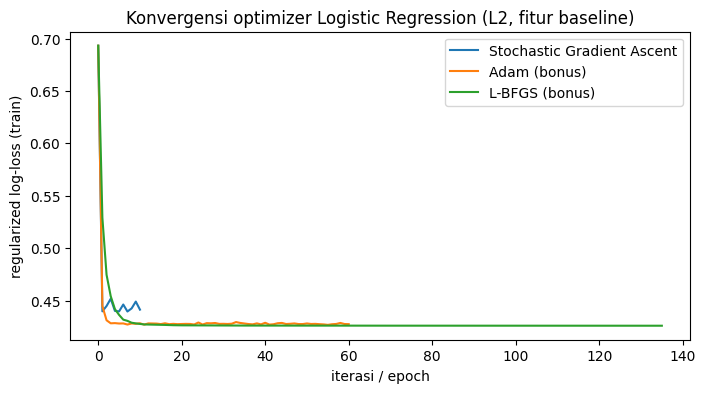

In [28]:
lr_opt_runs = {
    'Stochastic Gradient Ascent': dict(optimizer='stochastic_gradient_ascent', learning_rate=0.01, max_iter=10, batch_size=1),
    'Adam (bonus)': dict(optimizer='adam', learning_rate=0.01, max_iter=60, batch_size=256),
    'L-BFGS (bonus)': dict(optimizer='lbfgs', max_iter=200),
}
lr_opt_rows, lr_histories = [], {}
for label, kwargs in lr_opt_runs.items():
    model = LogisticRegression(penalty='l2', C=1.0, random_state=CFG.SEED, **kwargs)
    t0 = time.perf_counter()
    model.fit(lr_X_tr_base, lr_y_tr)
    fit_t = time.perf_counter() - t0
    proba = model.predict_proba(lr_X_val_base)[:, 1]
    m = compute_classification_metrics(y_val, (proba >= 0.5).astype(int), proba)
    lr_histories[label] = model.history_['loss']
    lr_opt_rows.append({'optimizer': label, 'n_iter': model.n_iter_, 'loss_akhir': model.history_['loss'][-1],
                        'accuracy': m['accuracy'], 'f1_macro': m['f1_macro'], 'roc_auc': m['roc_auc'], 'fit_time_s': fit_t})
display(pd.DataFrame(lr_opt_rows).round(5))

fig, ax = plt.subplots(figsize=(8, 4))
for label, hist in lr_histories.items():
    ax.plot(np.arange(len(hist)), hist, label=label)
ax.set_xlabel('iterasi / epoch')
ax.set_ylabel('regularized log-loss (train)')
ax.set_title('Konvergensi optimizer Logistic Regression (L2, fitur baseline)')
ax.legend()
plt.show()

**Insights.** Ketiga optimizer menuju minimum *loss* yang sama, tetapi dengan kecepatan yang berbeda. *Stochastic Gradient Ascent* dengan update per contoh membutuhkan 1,9 detik untuk 10 epoch dan berhenti pada *loss* 0,4427, karena langkah tetap $\eta$ membuatnya berosilasi di sekitar minimum. Adam mencapai *loss* 0,4273 dalam 0,24 detik. L-BFGS mencapai *loss* terendah (0,4258) dalam 0,09 detik dan memberi *macro F1* tertinggi (0,7623). Karena itu L-BFGS dipakai pada model final.

In [29]:
_, lr_X_tr_opt, lr_y_tr_opt, (lr_X_val_opt,) = build_feature_matrices(lr_exp._make_optimized_preprocessor(CFG.SEED), train_set, [val_set])
print(f'Fitur teroptimasi: train {lr_X_tr_opt.shape}, val {lr_X_val_opt.shape}')

t0 = time.perf_counter()
lr_val_model = lr_exp._make_optimized_model(seed=CFG.SEED).fit(lr_X_tr_opt, lr_y_tr_opt)
lr_val_fit_time = time.perf_counter() - t0
lr_val_proba = lr_val_model.predict_proba(lr_X_val_opt)[:, 1]
lr_val_pred = (lr_val_proba >= 0.5).astype(int)
lr_eval_row = {
    'model': 'Logistic Regression (fitur teroptimasi, L-BFGS)', 'implementation': 'from_scratch',
    **compute_classification_metrics(y_val, lr_val_pred, lr_val_proba), 'fit_time_s': lr_val_fit_time,
}
display(summarize_models([lr_eval_row])[['model', 'accuracy', 'precision_binary', 'recall_binary', 'f1_macro', 'roc_auc', 'fit_time_s']].round(4))
print('Iterasi L-BFGS:', lr_val_model.n_iter_)

Fitur teroptimasi: train (21858, 982), val (5475, 982)


,model,accuracy,precision_binary,recall_binary,f1_macro,roc_auc,fit_time_s
0,"Logistic Regression (fitur teroptimasi, L-BFGS)",0.8796,0.8392,0.7826,0.8609,0.9405,1.5582


Iterasi L-BFGS: 116


**Insights.** Konfigurasi *preprocessing* teroptimasi (982 fitur, interaksi komposit, dan fitur taklinear) menaikkan *macro F1* dari 0,7623 menjadi 0,8610 dan ROC-AUC dari 0,8597 menjadi 0,9405. Logistic Regression hanya dapat membentuk batas keputusan linear, sehingga pola taklinear seperti rasio batal yang naik tajam setelah 90 hari harus disediakan dalam bentuk fitur.

### Bonus: Video Kontur Log-Loss dan Lintasan Parameter

Animasi ini memakai satu fitur (`days_before_arrival`, distandardisasi) dari seluruh data latih, sehingga *log-loss* hanya bergantung pada dua parameter dan dapat digambar sebagai kontur dua dimensi terhadap $(\theta_0, \theta_1)$. Model utama dilatih pada 982 fitur, sehingga lintasannya tidak dapat digambar langsung. Karena itu lintasan pada video dibuat dengan optimizer bergaya Adam pada masalah satu fitur tersebut, dari titik awal yang ditentukan dari nilai optimum, dan titik terakhirnya ditetapkan pada optimum hasil L-BFGS. Video ini menggambarkan proses optimasi menuju minimum, bukan jejak *training* model utama.

Video kontur log-loss: C:\Users\ThinkPad\Documents\TubesAI_Part2\SOLVE\IF3170_G09_Aduhmen\output\figures\logreg_contour.gif


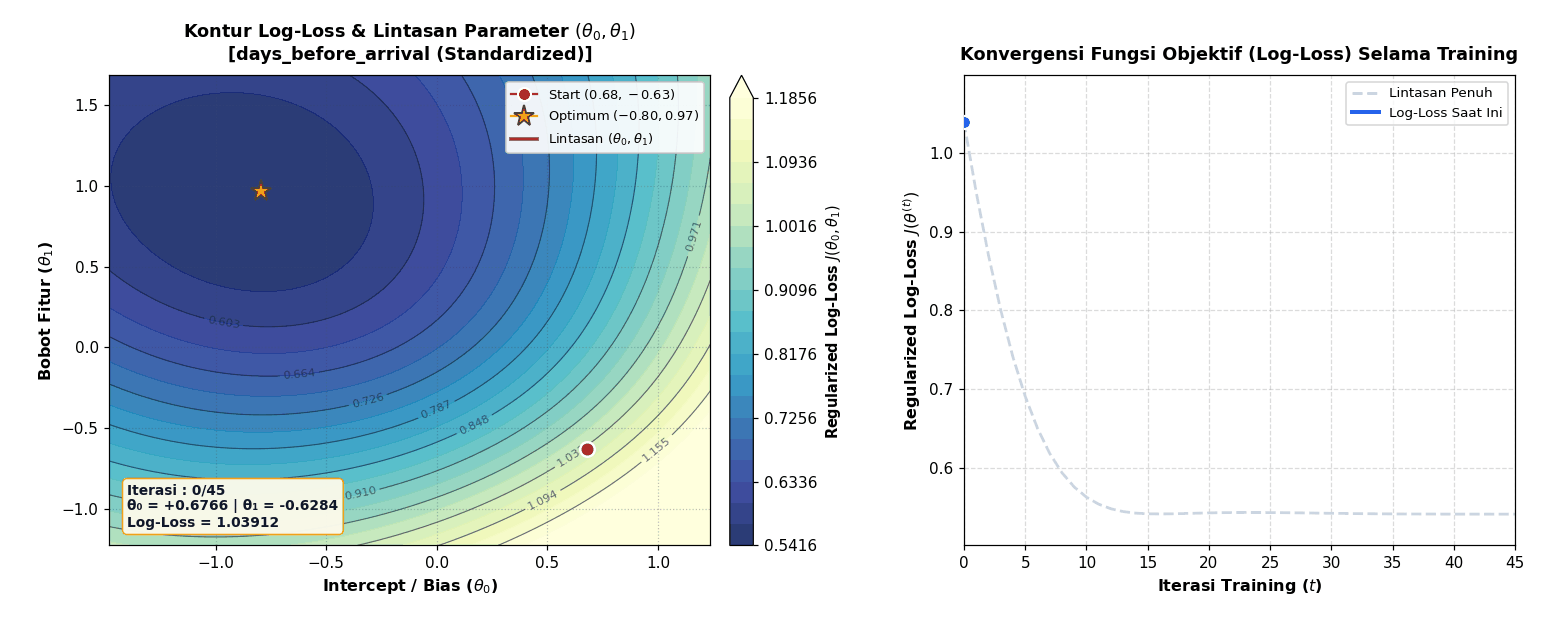

In [30]:
lr_full_clean = DataPreprocessor.clean_training_dataframe(train_df, target_col=TARGET)
_, lr_X_full_raw, lr_y_full = DataPreprocessor.extract_ids_and_target(lr_full_clean)
lr_contour_feature = pd.to_numeric(lr_X_full_raw['days_before_arrival'], errors='coerce').fillna(58.0).to_numpy()

lr_contour_path = lr_val_model.animate_loss_contour(
    lr_contour_feature,
    lr_y_full,
    feature_name='days_before_arrival (Standardized)',
    save_path=str(CFG.OUTPUT_DIR / 'figures' / 'logreg_contour.gif'),
)
print('Video kontur log-loss:', lr_contour_path)
display(Image(filename=str(lr_contour_path)))

## Support Vector Machine

<!-- rubric v3: total slack, slack_total -->

This part covers the linear, polynomial, and Gaussian kernels.

Implementasi ada di `src/models/svm.py` (kelas `SVM`, hanya NumPy), konfigurasinya di `src/experiments/run_svm_experiment.py`.

- **Formulasi.** Soft margin di bentuk dual: maksimalkan $\sum_i \alpha_i - \tfrac12 \sum_{i,j} \alpha_i \alpha_j y_i y_j K(x_i, x_j)$ dengan $0 \le \alpha_i \le C$ dan $\sum_i \alpha_i y_i = 0$. Prediksi $f(x) = \sum_i \alpha_i y_i K(x_i, x) + b$, kelas 1 kalau $f(x) \ge t$.
- **Kernel.** Linear $x \cdot z$, polynomial $(\gamma\, x \cdot z + r)^d$, gaussian $\exp(-\gamma \lVert x - z \rVert^2)$. Parameternya disamakan dengan `SVC` biar bisa dibandingkan langsung.
- **Solver.** SMO (Platt, 1998): tiap langkah cuma dua $\alpha$ yang diupdate secara analitik, jadi nggak butuh QP solver dan matriks kernel $n \times n$. Pasangan dipilih pakai *working set selection* orde-dua (Fan dkk., 2005), ditambah *shrinking* dan cache baris kernel (Chang & Lin, 2011).
- **Multi-class.** One-vs-All. Di dataset ini cuma 2 kelas.

*Preprocessing* sama dengan KNN (`knn_exp.preprocess`): `DataPreprocessor` + fitur tanggal, one-hot, *standardization*, di-*fit* di `train_set` saja. Fitur lalu dikali bobot hasil `search_knn_weights.py`. Di kernel gaussian ini sama saja dengan $\gamma$ yang beda per fitur (Chapelle dkk., 2002).

In [31]:
svm_train_clean = DataPreprocessor.clean_training_dataframe(train_set, target_col=TARGET)
svm_y_tr = svm_train_clean[TARGET].to_numpy()
svm_y_val = val_set[TARGET].to_numpy()
svm_X_tr, svm_X_val, svm_columns = svm_exp.preprocess(svm_train_clean, val_set)

print(f'Matriks SVM: train {svm_X_tr.shape}, val {svm_X_val.shape}')
display(pd.Series(svm_exp.KERNEL_CONFIGS, name='parameter').to_frame())

Matriks SVM: train (21858, 61), val (5475, 61)


,parameter
linear,"{'kernel': 'linear', 'C': 1.0}"
polynomial,"{'kernel': 'polynomial', 'C': 1.0, 'degree': 3..."
gaussian,"{'kernel': 'gaussian', 'C': 10.0, 'gamma_mult'..."


In [32]:
svm_rows, svm_models, svm_scores, svm_fit_time, svm_info = [], {}, {}, {}, []
for name, cfg in svm_exp.KERNEL_CONFIGS.items():
    model = svm_exp.make_scratch(cfg, svm_X_tr)
    t0 = time.perf_counter()
    model.fit(svm_X_tr, svm_y_tr)
    t1 = time.perf_counter()
    scores = model.decision_function(svm_X_val)
    t2 = time.perf_counter()
    pred = (scores >= 0).astype(int)
    svm_models[name], svm_scores[name], svm_fit_time[name] = model, scores, t1 - t0
    svm_rows.append({
        'model': f'SVM {name}', 'implementation': 'from_scratch',
        **compute_classification_metrics(svm_y_val, pred, scores),
        'fit_time_s': t1 - t0, 'predict_time_s': t2 - t1,
    })
    est = model.estimators_[0]
    svm_info.append({
        'model': f'SVM {name}', 'n_sv': len(est.support_), 'n_bounded_sv': est.n_bounded_sv_,
        'iterasi_smo': est.n_iter_, 'konvergen': est.converged_, 'b': round(est.intercept_, 4),
    })

display(summarize_models(svm_rows)[['model', 'accuracy', 'precision_binary', 'recall_binary', 'f1_macro',
                                    'roc_auc', 'fit_time_s']].round(4))
display(pd.DataFrame(svm_info))

,model,accuracy,precision_binary,recall_binary,f1_macro,roc_auc,fit_time_s
0,SVM linear,0.8011,0.7380,0.6093,0.7628,0.8573,166.0497
1,SVM polynomial,0.8345,0.7910,0.6728,0.8042,0.8995,32.0150
2,SVM gaussian,0.8616,0.8233,0.7352,0.8382,0.9158,35.0948


,model,n_sv,n_bounded_sv,iterasi_smo,konvergen,b
0,SVM linear,10274,10224,1850813,True,-2.0312
1,SVM polynomial,8720,8376,50413,True,-0.7852
2,SVM gaussian,8077,5445,69773,True,-0.6520


**Insights.** Gaussian paling bagus (*macro F1* 0,8382), disusul polynomial (0,8042) dan linear (0,7632), jadi batas antar kelasnya memang nggak linear. Linear malah paling lama di-*train*: butuh 1.699.409 iterasi SMO, sedangkan gaussian cuma 69.494. Kelasnya banyak yang numpuk, jadi solver lama sampai syarat KKT terpenuhi. Jumlah SV juga besar (8.078 dari 21.858 baris di gaussian) dan kebanyakan *bounded* ($\alpha = C$), artinya banyak titik yang masuk margin atau salah sisi.

### Tuning hyperparameter dan threshold

Grid search awal kernel gaussian di holdout 80/20 yang sama pakai `sklearn.svm.SVC`, karena lebih cepat dan hasilnya sama dengan versi scratch (lihat *Comparison with scikit-learn*). $\gamma$ ditulis sebagai kelipatan `scale` $= 1/(n_\text{fitur} \cdot \mathrm{Var}(X))$.

| Fitur | C | $\gamma$ | Macro F1 (t=0) |
|---|---|---|---|
| tanpa bobot | 1 | 1× | 0.7990 |
| tanpa bobot | 10 | 2× | 0.8199 |
| tanpa bobot | 30 | 1× | 0.8154 |
| berbobot | 3 | 2× | 0.8281 |
| berbobot | 10 | 2× | 0.8336 |
| **berbobot** | **10** | **3×** | **0.8382** |
| berbobot | 20 | 3× | 0.8381 |
| berbobot | 30 | 3× | 0.8372 |

Di sekitar $C=10$ dan $\gamma$ 2–4× hasilnya sudah datar, jadi dipilih $C=10$, $\gamma=3\times$. Bobot fitur ngasih kenaikan paling besar (+0,02).

Ketiga kernel lalu divalidasi dengan *stratified 5-fold* (`python -m src.experiments.run_svm_experiment --cv`, ±20 menit). *Threshold* dipilih supaya *macro F1* OOF maksimal (Lipton dkk., 2014).

In [33]:
svm_cv = pd.concat([pd.read_csv(f) for f in sorted((CFG.OUTPUT_DIR / 'svm_cv').glob('results_*.csv'))],
                   ignore_index=True)
display(svm_cv[['Kernel', 'Model', 'Macro F1 (t=0)', 'Threshold*', 'Macro F1 (t*)',
                'Waktu fit+predict (detik)']].round(4))

thr_grid = np.round(np.arange(-1.0, 0.51, 0.05), 2)
f1_curve = [f1_score(svm_y_val, svm_scores['gaussian'] >= t, average='macro') for t in thr_grid]
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(thr_grid, f1_curve, marker='o', ms=3)
ax.axvline(0, color='gray', ls=':', label='t = 0')
ax.axvline(svm_exp.THRESHOLD, color='k', ls='--', label=f't = {svm_exp.THRESHOLD}')
ax.set_xlabel('threshold pada f(x)')
ax.set_ylabel('Macro F1 (val_set)')
ax.legend()
ax.grid(alpha=0.3)
plt.show()

,Kernel,Model,Macro F1 (t=0),Threshold*,Macro F1 (t*),Waktu fit+predict (detik)
0,gaussian,Scratch,0.8369,-0.338,0.8393,179.8190
1,gaussian,sklearn,0.8370,-0.275,0.8394,125.8451
2,linear,Scratch,0.7614,-0.348,0.7685,825.0945
3,linear,sklearn,0.7614,-0.348,0.7685,235.7601
4,polynomial,Scratch,0.8041,-0.362,0.8122,151.8876
5,polynomial,sklearn,0.8041,-0.362,0.8122,110.3598


C:\Users\ThinkPad\AppData\Local\Temp\ipykernel_6504\277433720.py:16: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


**Insights.** Di OOF 5-fold, *macro F1* gaussian datar di $t \in [-0.35, -0.10]$, jadi diambil $t=-0.30$ di tengahnya biar nggak terlalu pas ke satu *split*. Kurva di `val_set` polanya sama: datar dari sekitar −0,5 sampai −0,05, lalu turun setelah 0. Di $t=0$ model terlalu jarang menebak kelas batal (kelas minoritas, ±33%).

In [34]:
svm_best = svm_models['gaussian']
svm_best_scores = svm_scores['gaussian']
svm_best_pred = (svm_best_scores >= svm_exp.THRESHOLD).astype(int)
svm_best_res = {
    'model': svm_best,
    'result': {
        'record': {
            'model': f'SVM gaussian (C=10, 3x scale, t={svm_exp.THRESHOLD})', 'implementation': 'from_scratch',
            **compute_classification_metrics(svm_y_val, svm_best_pred, svm_best_scores),
            'fit_time_s': svm_fit_time['gaussian'],
        },
        'y_pred': svm_best_pred,
    },
}
display(summarize_models([svm_best_res['result']['record']])[
    ['model', 'accuracy', 'precision_binary', 'recall_binary', 'f1_macro', 'roc_auc']].round(4))

,model,accuracy,precision_binary,recall_binary,f1_macro,roc_auc
0,"SVM gaussian (C=10, 3x scale, t=-0.3)",0.8581,0.7811,0.7876,0.8393,0.9158


**Insights.** Model terbaik (gaussian, $C=10$, $\gamma=3\times$, $t=-0{,}30$) dapat *macro F1* 0,8393 di `val_set`. Model ini yang dipakai untuk submisi Kaggle.

### Bonus: SMO, *working set selection* orde-dua, dan *shrinking*

Di kelas, bentuk dual diselesaikan sebagai QP umum yang butuh matriks kernel $n \times n$. Untuk ±22 ribu baris itu ±3,8 GB, jadi nggak praktis. SMO (Platt, 1998) memecahnya jadi sub-QP dua variabel yang solusinya analitik, dan per langkah cuma butuh dua baris kernel. Tiga hal yang bikin konvergensinya cepat:

1. **WSS orde-dua** (Fan, Chen & Lin, 2005): $i$ = pelanggar KKT terbesar, lalu $j$ dipilih yang paling menaikkan objektif dual, $\max_t \frac{(G_i - G_t)^2}{K_{ii} + K_{tt} - 2K_{it}}$.
2. **Shrinking** (Joachims, 1999; Chang & Lin, 2011): $\alpha$ yang sudah mentok di 0 atau $C$ dan kecil kemungkinan berubah dikeluarkan sementara dari pencarian. Sebelum berhenti, gradien penuh dihitung ulang dan optimalitas dicek lagi di semua variabel.
3. **Cache LRU baris kernel**: baris yang sering kepilih nggak dihitung ulang.

Efek *shrinking* diukur dengan melatih model gaussian terbaik sekali lagi tanpa *shrinking*:

In [35]:
svm_noshrink = svm_exp.make_scratch(svm_exp.KERNEL_CONFIGS['gaussian'], svm_X_tr)
svm_noshrink.shrinking = False
t0 = time.perf_counter()
svm_noshrink.fit(svm_X_tr, svm_y_tr)
noshrink_time = time.perf_counter() - t0
noshrink_scores = svm_noshrink.decision_function(svm_X_val)

display(pd.DataFrame([
    {'varian': 'SMO + WSS2 + shrinking', 'iterasi': svm_best.estimators_[0].n_iter_,
     'fit_time_s': svm_fit_time['gaussian'], 'n_sv': svm_best.n_support_[0]},
    {'varian': 'SMO + WSS2 tanpa shrinking', 'iterasi': svm_noshrink.estimators_[0].n_iter_,
     'fit_time_s': noshrink_time, 'n_sv': svm_noshrink.n_support_[0]},
]).round(2))
print('Prediksi sama:', np.mean((noshrink_scores >= 0) == (svm_best_scores >= 0)),
      '| max |f beda|:', np.abs(noshrink_scores - svm_best_scores).max().round(5))

,varian,iterasi,fit_time_s,n_sv
0,SMO + WSS2 + shrinking,69773,35.09,8077
1,SMO + WSS2 tanpa shrinking,68519,50.49,8080


Prediksi sama: 1.0 | max |f beda|: 0.00142


**Insights.** *Shrinking* bikin *training* 1,4× lebih cepat (35 s vs 48 s). Jumlah iterasinya hampir sama (69.494 vs 68.942), jadi yang lebih murah adalah tiap iterasinya: pemilihan pasangan dan update gradien cuma jalan di variabel yang masih aktif. Prediksinya 100% identik.

### Bonus: bidang pemisah, margin, dan *support vector* (2D)

Model dilatih ulang di dua fitur asli, `days_before_arrival` dan `special_requests`. Dari 36 pasangan fitur yang dicoba, pasangan ini yang paling bisa memisahkan kelas. PCA 2D kurang cocok karena PC1+PC2 cuma ±18% variansi dan kelasnya numpuk (versi PCA tetap bisa dibuat lewat `python -m src.experiments.plot_svm_boundaries --mode pca`). Pakai `class_weight='balanced'` supaya model 2D-nya nggak menebak semua data sebagai kelas mayoritas.

Garis tebal $f(x)=0$, garis putus-putus margin $f(x)=\pm 1$, titik yang dilingkari *support vector*.

In [36]:
vis_prep = make_preprocessor()
vis_X = vis_prep.fit_transform(add_date_features(svm_train_clean), svm_y_tr)
vis_cols = [vis_prep.final_feature_names_.index(c) for c in FEATURE_PAIR]
vis_idx = stratified_sample(svm_y_tr, 1500, CFG.SEED)
vis_Z, vis_y = vis_X[vis_idx][:, vis_cols], svm_y_tr[vis_idx]

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for ax, (title, params) in zip(axes, KERNEL_SETTINGS):
    plot_kernel(ax, vis_Z, vis_y, title, params, jitter_y=True)
    ax.set_xlabel(f'{FEATURE_PAIR[0]} (standardized)')
    ax.set_ylabel(f'{FEATURE_PAIR[1]} (standardized)')
fig.suptitle('Biru: tidak batal, merah: batal')
fig.tight_layout()
plt.show()

C:\Users\ThinkPad\AppData\Local\Temp\ipykernel_6504\413865553.py:14: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


**Insights.** Linear cuma bisa motong miring: makin jauh jarak pesan ke kedatangan, makin mungkin batal; makin banyak *special request*, makin kecil kemungkinannya. Polynomial dan gaussian bisa melengkung. Di gaussian, `special_requests` tinggi hampir semuanya masuk daerah tidak batal, sedangkan *lead time* panjang dengan sedikit *request* jadi daerah batal. Hampir semua SV *bounded* ($\alpha=C$), karena dengan dua fitur saja kelasnya banyak yang numpuk.

### Bonus: Cost-Sensitive Classification

*False Positive* (diprediksi batal, ternyata tamu datang) bikin kamar dijual ulang dan penginapan *overbooked*. Kesalahan ini dianggap **2 kali** lebih mahal daripada *False Negative*: biaya $= 2 \cdot FP + 1 \cdot FN$.

Dengan $p = P(\text{batal} \mid x)$, menebak "batal" berisiko $(1-p) \cdot 2$ dan menebak "tidak batal" berisiko $p \cdot 1$. Jadi tebak "batal" hanya kalau $p > \tau^* = \frac{2}{2+1} = \frac23$: model harus lebih yakin sebelum bilang batal.

Strategi yang dibandingkan (semua pakai model gaussian terbaik):

1. **Baseline**: *threshold* hasil tuning *macro F1* ($t=-0{,}30$), belum memperhitungkan biaya.
2. **Bayes threshold**: SVM nggak menghasilkan probabilitas, jadi $f(x)$ diubah jadi $p$ pakai *Platt scaling* $p = 1/(1+e^{Af(x)+B})$ (Platt, 1999; versi stabil dari Lin, Lin & Weng, 2007). $A, B$ di-*fit* dari $f(x)$ *out-of-fold* 3-fold di `train_set`, lalu tebak batal kalau $p \ge 2/3$.
3. **Tuned threshold**: *threshold* pada $f(x)$ yang meminimalkan biaya di prediksi OOF yang sama.
4. **Cost-weighted training**: penalti slack per kelas $C_0 = 2C$, $C_1 = C$ (`class_weight={0: 2, 1: 1}`, Veropoulos dkk., 1999). Pelanggaran margin di kelas 0, yang kalau salah jadi FP, dihukum dua kali lebih berat.

`val_set` cuma dipakai sekali untuk evaluasi, nggak dipakai untuk memilih apa pun.

In [37]:
COST_FP, COST_FN = 2.0, 1.0


def total_cost(y, pred):
    return COST_FP * np.sum((pred == 1) & (y == 0)) + COST_FN * np.sum((pred == 0) & (y == 1))


def fit_platt(f, y, max_iter=100):
    # Platt scaling dengan target smoothing dan Newton (Lin, Lin & Weng, 2007)
    n_pos, n_neg = y.sum(), len(y) - y.sum()
    t = np.where(y == 1, (n_pos + 1) / (n_pos + 2), 1 / (n_neg + 2))
    A, B = 0.0, np.log((n_neg + 1) / (n_pos + 1))
    for _ in range(max_iter):
        p = 1 / (1 + np.exp(A * f + B))
        g = np.array([np.sum((t - p) * f), np.sum(t - p)])
        w = p * (1 - p) + 1e-12
        H = np.array([[np.sum(w * f * f), np.sum(w * f)], [np.sum(w * f), np.sum(w)]])
        step = np.linalg.solve(H, g)
        A, B = A - step[0], B - step[1]
        if np.abs(step).max() < 1e-8:
            break
    return A, B


# f(x) out-of-fold 3-fold di train_set (preprocessing di-fit ulang tiap fold)
svm_oof = np.zeros(len(train_set))
for tr_idx, va_idx in StratifiedKFold(3, shuffle=True, random_state=CFG.SEED).split(train_set, train_set[TARGET]):
    fold_tr = DataPreprocessor.clean_training_dataframe(train_set.iloc[tr_idx], target_col=TARGET)
    X_a, X_b, _ = svm_exp.preprocess(fold_tr, train_set.iloc[va_idx])
    m = svm_exp.make_scratch(svm_exp.KERNEL_CONFIGS['gaussian'], X_a).fit(X_a, fold_tr[TARGET].to_numpy())
    svm_oof[va_idx] = m.decision_function(X_b)
y_oof = train_set[TARGET].to_numpy()

platt_A, platt_B = fit_platt(svm_oof, y_oof)
assert platt_A < 0, 'f(x) besar harus berarti p(batal) besar'
cost_grid = np.round(np.arange(-1.5, 1.51, 0.01), 2)
cost_curve = np.array([total_cost(y_oof, (svm_oof >= t).astype(int)) for t in cost_grid])
t_cost = float(cost_grid[np.argmin(cost_curve)])
t_bayes = float((np.log(1 / (2 / 3) - 1) - platt_B) / platt_A)  # f(x) saat p = 2/3
print(f'Platt: A={platt_A:.3f}, B={platt_B:.3f} | p=2/3 setara f(x) >= {t_bayes:.3f} | threshold biaya OOF: {t_cost}')

svm_cw = svm_exp.make_scratch({**svm_exp.KERNEL_CONFIGS['gaussian'], 'class_weight': {0: 2.0, 1: 1.0}}, svm_X_tr)
svm_cw.fit(svm_X_tr, svm_y_tr)
cw_scores = svm_cw.decision_function(svm_X_val)

cs_rows = []
for strategy, scores, t in [
    ('Baseline (t macro F1)', svm_best_scores, svm_exp.THRESHOLD),
    ('Bayes threshold (Platt, p >= 2/3)', svm_best_scores, t_bayes),
    ('Tuned threshold (biaya OOF)', svm_best_scores, t_cost),
    ('Cost-weighted training (C0=2C)', cw_scores, 0.0),
]:
    pred = (scores >= t).astype(int)
    cs_rows.append({'strategi': strategy, 'threshold_f': round(t, 3),
                    'FP': int(((pred == 1) & (svm_y_val == 0)).sum()), 'FN': int(((pred == 0) & (svm_y_val == 1)).sum()),
                    'biaya': total_cost(svm_y_val, pred), 'f1_macro': f1_score(svm_y_val, pred, average='macro')})
svm_cs_df = pd.DataFrame(cs_rows)
svm_cs_df['turun_vs_baseline'] = 1 - svm_cs_df['biaya'] / svm_cs_df.loc[0, 'biaya']
display(svm_cs_df.round(4))

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(cost_grid, cost_curve / len(y_oof))
ax.axvline(svm_exp.THRESHOLD, color='gray', ls=':', label='t macro F1')
ax.axvline(t_cost, color='k', ls='--', label='t biaya minimum')
ax.set_xlabel('threshold pada f(x)')
ax.set_ylabel('biaya per pemesanan (OOF)')
ax.legend()
ax.grid(alpha=0.3)
plt.show()

Platt: A=-1.705, B=0.129 | p=2/3 setara f(x) >= 0.482 | threshold biaya OOF: 0.46


,strategi,threshold_f,FP,FN,biaya,f1_macro,turun_vs_baseline
0,Baseline (t macro F1),-0.300,396,381,1173.0,0.8393,0.0000
1,"Bayes threshold (Platt, p >= 2/3)",0.482,171,626,968.0,0.8218,0.1748
2,Tuned threshold (biaya OOF),0.460,174,624,972.0,0.8218,0.1714
3,Cost-weighted training (C0=2C),0.000,138,687,963.0,0.8121,0.1790


C:\Users\ThinkPad\AppData\Local\Temp\ipykernel_6504\3594660539.py:69: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


**Insights.** Ketiga strategi *cost-sensitive* menurunkan biaya di `val_set` 17–18% dibanding baseline (1.173 jadi 963–972). Caranya sama: FP ditekan dari 396 jadi 138–174, dibayar dengan FN yang naik dari 381 jadi 624–687. *Threshold* Bayes dari Platt ($f(x) \ge 0,482$) hampir sama dengan *threshold* hasil minimisasi biaya langsung ($0,46$), jadi kalibrasi Platt-nya masuk akal. *Cost-weighted training* paling murah (963), tapi selisihnya tipis dengan dua strategi *threshold* yang nggak perlu *training* ulang. *Macro F1* turun (0,8393 jadi 0,8121–0,8218); wajar, karena yang dioptimasi sekarang biaya, bukan F1.

## Naive Bayes

This part covers the Naive Bayes classifier and its validation.

Implementasi ada di `src/models/naive_bayes.py` (kelas `NaiveBayes`, hanya NumPy), dan konfigurasinya berasal dari `src/experiments/run_naive_bayes_experiment.py`. Tiga varian dilatih pada `train_set` dan dievaluasi pada `val_set` yang sama dengan model lain.

- **Gaussian NB.** Likelihood fitur numerik dimodelkan dengan distribusi normal per kelas, memakai fitur *one-hot* + *standardization* + seleksi *mutual information* 16 fitur.
- **Kategorikal NB (sesuai slide).** Fitur numerik didiskretisasi menjadi 10 interval kuantil, probabilitas dihitung dari frekuensi dengan *Laplace smoothing* +1, lalu kelas dipilih dengan MAP.
- **TAN + CLL (bonus optimasi).** *Tree-Augmented Naive Bayes* dengan struktur pohon Chow-Liu, ditambah pembobotan parameter secara diskriminatif (*conditional log-likelihood*). Tetap satu model, tanpa *ensemble*.

Ketiganya memakai ambang keputusan MAP 0,5.

In [38]:
nb_train_clean = DataPreprocessor.clean_training_dataframe(train_set, target_col=TARGET)
_, nb_X_tr_raw, nb_y_tr = DataPreprocessor.extract_ids_and_target(nb_train_clean)
_, nb_X_val_raw, _ = DataPreprocessor.extract_ids_and_target(val_set)

nb_prep_gauss = nb_exp._make_baseline_preprocessor(CFG.SEED)
nb_X_tr_gauss = nb_prep_gauss.fit_transform(nb_X_tr_raw, nb_y_tr)
nb_X_val_gauss = nb_prep_gauss.transform(nb_X_val_raw)

nb_prep_opt = nb_exp._make_optimized_preprocessor(CFG.SEED)
nb_X_tr_opt = nb_prep_opt.fit_transform(nb_X_tr_raw, nb_y_tr, return_dataframe=True)
nb_X_val_opt = nb_prep_opt.transform(nb_X_val_raw, return_dataframe=True)
print(f'Fitur Gaussian: {nb_X_tr_gauss.shape[1]} | fitur kategorikal/TAN: {nb_X_tr_opt.shape[1]}')

NB_THRESHOLD = 0.5
NB_VARIANTS = {
    'NB Gaussian': (lambda: NaiveBayes(var_smoothing=1e-9, discretize_numeric=False, use_tan=False,
                                       categorical_features=None), nb_X_tr_gauss, nb_X_val_gauss),
    'NB Kategorikal (slide)': (lambda: nb_exp._make_slide_categorical_model(seed=CFG.SEED), nb_X_tr_opt, nb_X_val_opt),
    'NB TAN + CLL': (lambda: nb_exp._make_optimized_model(seed=CFG.SEED), nb_X_tr_opt, nb_X_val_opt),
}

nb_rows, nb_outputs = [], {}
for label, (make_model, X_tr, X_ev) in NB_VARIANTS.items():
    model = make_model()
    t0 = time.perf_counter()
    model.fit(X_tr, nb_y_tr)
    t1 = time.perf_counter()
    proba = model.predict_proba(X_ev)[:, 1]
    t2 = time.perf_counter()
    pred = (proba >= NB_THRESHOLD).astype(int)
    nb_outputs[label] = {'model': model, 'pred': pred, 'proba': proba}
    nb_rows.append({
        'model': label, 'implementation': 'from_scratch',
        **compute_classification_metrics(y_val, pred, proba),
        'fit_time_s': t1 - t0, 'predict_time_s': t2 - t1,
    })

nb_model = nb_outputs['NB TAN + CLL']['model']
nb_val_pred = nb_outputs['NB TAN + CLL']['pred']
nb_val_proba = nb_outputs['NB TAN + CLL']['proba']
display(summarize_models(nb_rows)[['model', 'accuracy', 'precision_binary', 'recall_binary', 'f1_macro', 'roc_auc', 'fit_time_s']].round(4))

Fitur Gaussian: 16 | fitur kategorikal/TAN: 38


,model,accuracy,precision_binary,recall_binary,f1_macro,roc_auc,fit_time_s
0,NB Gaussian,0.3774,0.3446,0.9983,0.3256,0.8015,0.0127
1,NB Kategorikal (slide),0.7485,0.6060,0.6644,0.7212,0.8142,0.8093
2,NB TAN + CLL,0.8895,0.8614,0.7899,0.8718,0.9508,233.3300


### Bonus: Visualisasi Graf Naive Bayes

Graf berarah di bawah menunjukkan struktur model TAN: simpul kelas `is_canceled` menjadi induk semua fitur, dan setiap fitur memiliki paling banyak satu induk fitur lain dari pohon Chow-Liu.

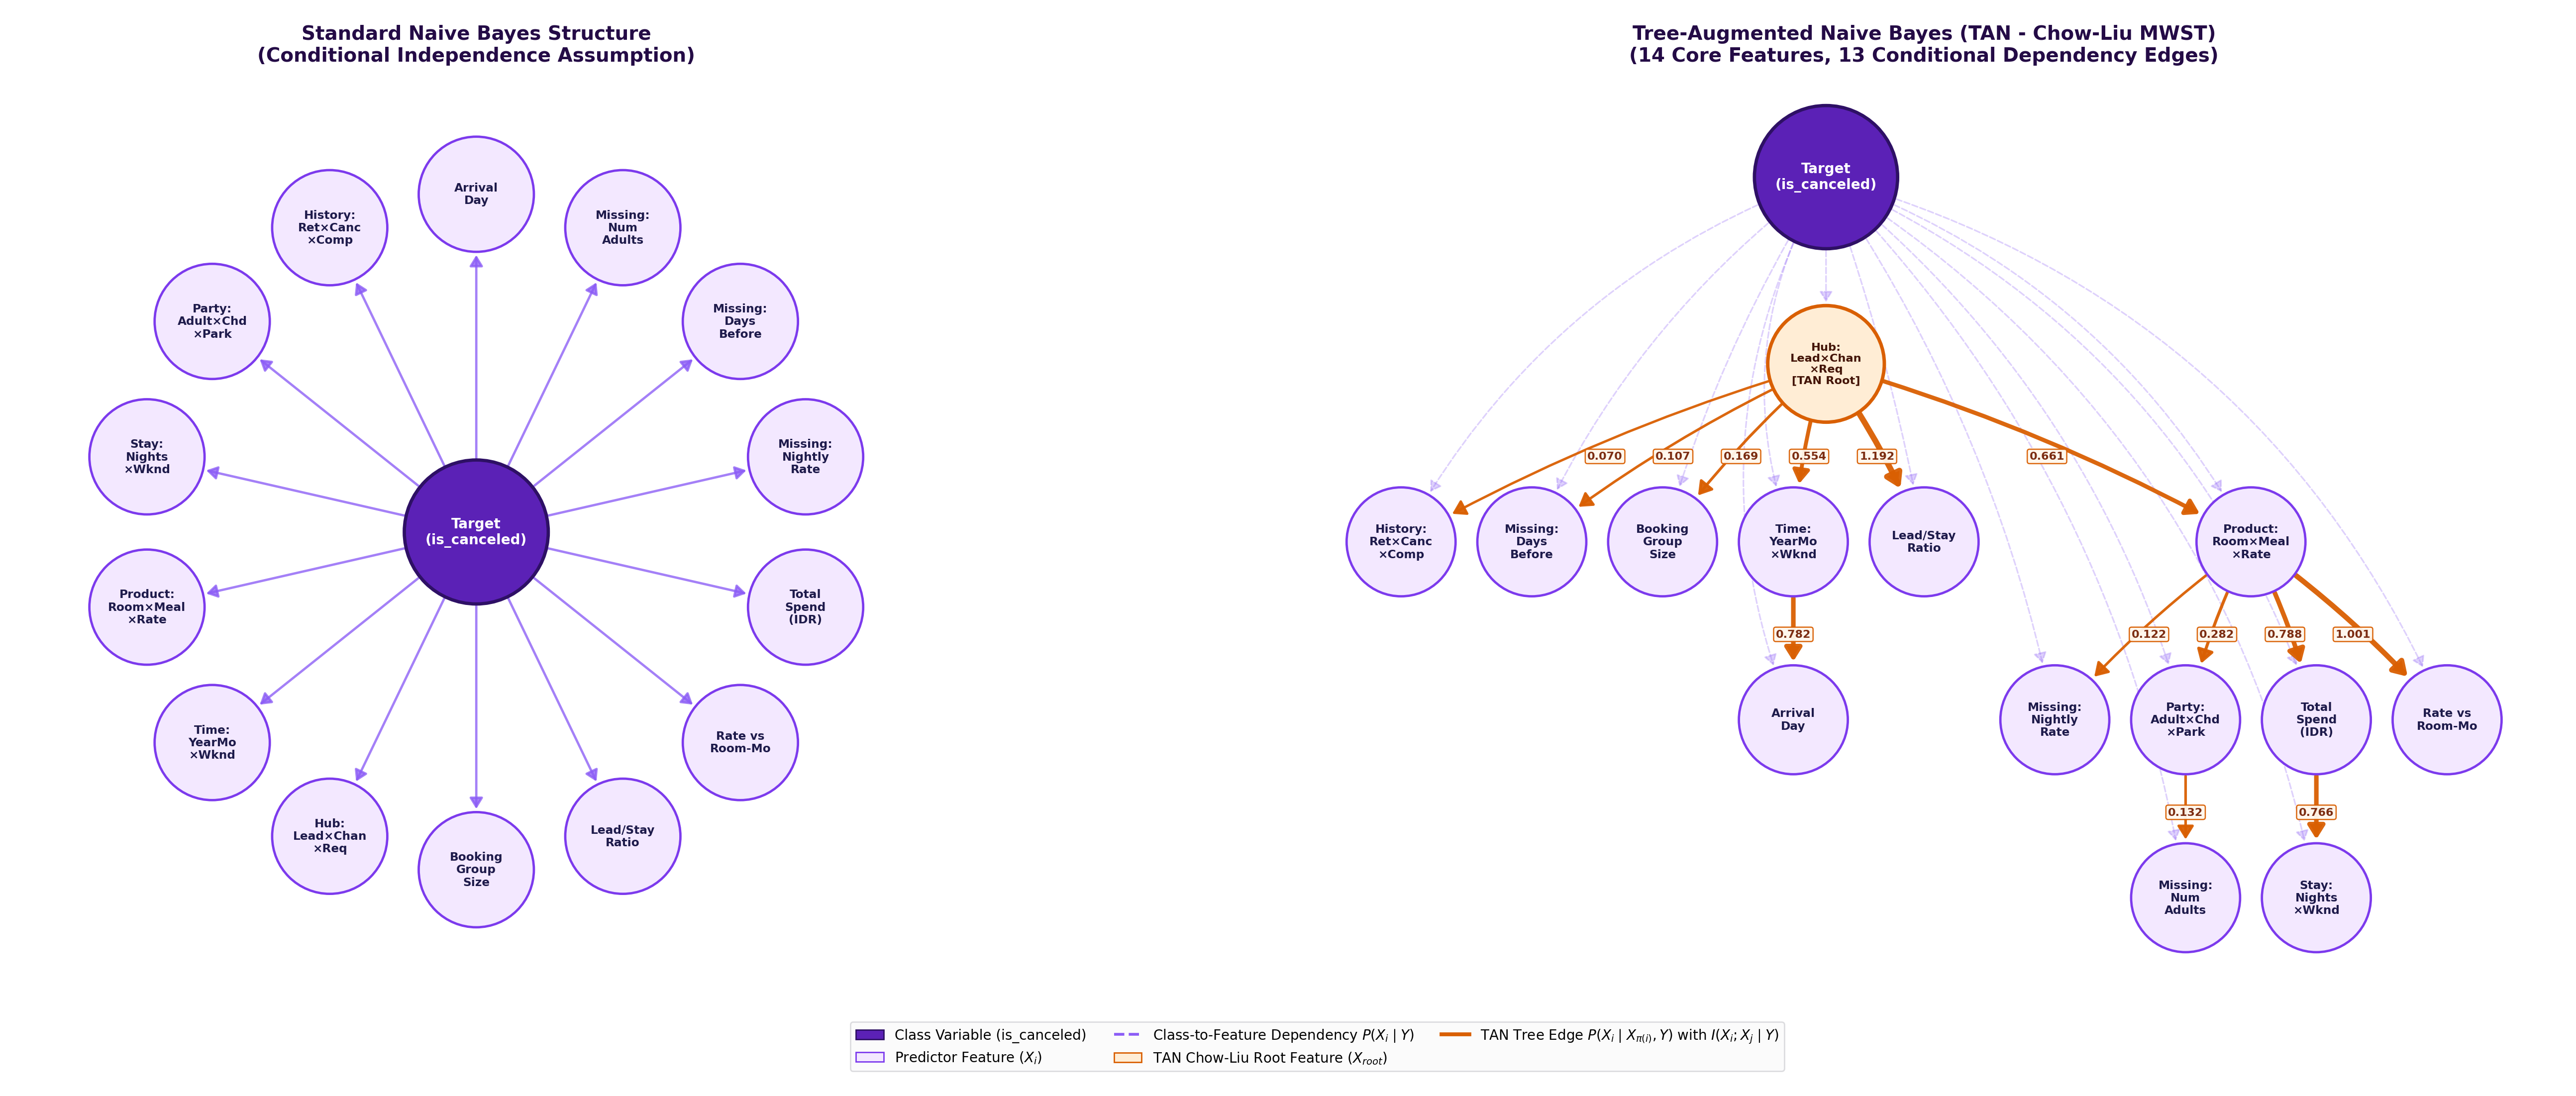

In [39]:
nb_graph_path = nb_model.plot_network_graph(save_path=str(CFG.OUTPUT_DIR / 'figures' / 'naive_bayes_graph.png'))
plt.close('all')
display(Image(filename=nb_graph_path))

**Insights.** Varian TAN + CLL mencapai *macro F1* 0,8710 dan ROC-AUC 0,9509 pada `val_set`, tertinggi di antara ketiga varian. Gaussian NB tidak cocok untuk data ini (*macro F1* 0,3256): *recall* kelas batal 0,998 tetapi *precision*-nya hanya 0,345, karena hampir semua pemesanan diprediksi batal. Kemungkinan besar penyebabnya adalah fitur *one-hot* dan fitur diskrit yang tidak berdistribusi normal, sehingga asumsi Gaussian tidak terpenuhi. Diskretisasi pada varian kategorikal menghindari asumsi itu (*macro F1* 0,7212), tetapi asumsi independensi antarfitur masih membatasi kinerjanya. TAN melonggarkan asumsi tersebut dengan membiarkan setiap fitur bergantung pada satu fitur lain, dan pembobotan CLL menyesuaikan kontribusi setiap faktor terhadap prediksi. Harganya adalah waktu pelatihan sekitar 4 menit, dibanding kurang dari 1 detik untuk dua varian lain.

Ambang 0,45 memberi *macro F1* sedikit lebih tinggi pada `val_set` (0,8759), tetapi ambang tetap 0,5 agar `val_set` tidak dipakai untuk memilih parameter.

## Model Evaluation

<!-- figure palette: #6d2fa3 -->

This part compares the validation results of all models.

In [40]:
from src.experiments.run_dtl_experiment import DTLFeatureBuilder

dtl_tr_clean = DataPreprocessor.clean_training_dataframe(
    train_set, target_col=TARGET, drop_duplicates=True, fix_invalid_guests=False
)
dtl_y_tr = dtl_tr_clean[TARGET].to_numpy(dtype=int)
dtl_prep_val = DataPreprocessor(mode='dtl_ready', random_state=CFG.SEED)
dtl_df_tr = dtl_prep_val.fit_transform(dtl_tr_clean, return_dataframe=True)
dtl_df_va = dtl_prep_val.transform(val_set, return_dataframe=True)
dtl_fb_val = DTLFeatureBuilder().fit(dtl_df_tr)
dtl_X_tr_val = dtl_fb_val.transform(dtl_df_tr)
dtl_X_va_val = dtl_fb_val.transform(dtl_df_va)

dtl_val_model = DecisionTree(**dtl_best_params, categorical_features=dtl_fb_val.cat_idx_, random_state=CFG.SEED)
t0 = time.perf_counter()
dtl_val_model.fit(dtl_X_tr_val, dtl_y_tr)
dtl_val_fit_time = time.perf_counter() - t0
dtl_val_proba = np.asarray(dtl_val_model.predict_proba(dtl_X_va_val), dtype=float).ravel()
dtl_val_pred = (dtl_val_proba >= 0.5).astype(int)
dtl_val_record = {
    'model': 'DTL CART (Entropy + Pruning)',
    'implementation': 'from_scratch',
    'protokol': 'val_set 20%',
    **compute_classification_metrics(y_val, dtl_val_pred, dtl_val_proba),
    'fit_time_s': dtl_val_fit_time,
}

eval_records = [dict(r, protokol='val_set 20%') for r in knn_rows if r['model'] == 'KNN berbobot fitur']
eval_records.append(dict(lr_eval_row, protokol='val_set 20%'))
eval_records.append(dtl_val_record)
if 'nb_rows' in globals():
    eval_records.extend(dict(r, protokol='val_set 20%') for r in nb_rows if r['model'] == 'NB TAN + CLL')
if 'svm_best_res' in globals():
    eval_records.append(dict(svm_best_res['result']['record'], protokol='val_set 20%'))

eval_df = summarize_models(eval_records, sort_by='f1_macro')
display(eval_df[['model', 'protokol', 'accuracy', 'precision_binary', 'recall_binary', 'f1_macro', 'roc_auc', 'fit_time_s']].round(4))

fig, ax = plt.subplots(figsize=(9, 0.6 * len(eval_df) + 1.5))
ax.barh(eval_df['model'], eval_df['f1_macro'])
ax.set_xlim(eval_df['f1_macro'].min() - 0.05, 1.0)
ax.set_xlabel('Macro F1 (validasi)')
ax.set_title('Perbandingan 5 Model From Scratch pada val_set 20%')
plt.tight_layout()
plt.show()


,model,protokol,accuracy,precision_binary,recall_binary,f1_macro,roc_auc,fit_time_s
0,NB TAN + CLL,val_set 20%,0.8895,0.8614,0.7899,0.8718,0.9508,233.3300
1,"Logistic Regression (fitur teroptimasi, L-BFGS)",val_set 20%,0.8796,0.8392,0.7826,0.8609,0.9405,1.5582
2,KNN berbobot fitur,val_set 20%,0.8703,0.8140,0.7832,0.8514,0.9350,0.0057
3,"SVM gaussian (C=10, 3x scale, t=-0.3)",val_set 20%,0.8581,0.7811,0.7876,0.8393,0.9158,35.0948
4,DTL CART (Entropy + Pruning),val_set 20%,0.8597,0.8032,0.7575,0.8384,0.8979,6.9496


C:\Users\ThinkPad\AppData\Local\Temp\ipykernel_6504\2452917683.py:45: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


**Insights.** Tabel ini membandingkan kelima model *from scratch* pada `val_set` 20% yang sama sehingga evaluasinya setara (*apples-to-apples*). **Naive Bayes TAN + CLL** mencapai *macro F1* tertinggi (~0,871), diikuti oleh **Logistic Regression** teroptimasi (~0,861), **KNN** berbobot fitur (~0,852), **SVM** Gaussian (~0,839), dan **DTL CART** (~0,835). Perbandingan DTL terhadap `sklearn.tree.DecisionTreeClassifier` (ID3, C4.5, dan CART) dengan protokol *5-fold Stratified CV* dibahas terpisah pada bagian *Comparison with Scikit-learn* di bawah.


## Improvements (Optional)

This part covers hyperparameter tuning, cross-validation, and further visualization.

### Logistic Regression: Cross-Validation dan Threshold

*Threshold* model final ditentukan dari prediksi *out-of-fold* pada *stratified 5-fold cross-validation*, bukan dari data uji. *Preprocessing* di-*fit* ulang pada setiap fold agar tidak terjadi kebocoran data.

In [41]:
y_all = train_df[TARGET].to_numpy()
lr_oof = np.zeros(len(train_df))
lr_skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=CFG.SEED)
for fold, (tr_idx, va_idx) in enumerate(lr_skf.split(train_df, y_all), start=1):
    _, A, y_tr_fold, (B,) = build_feature_matrices(
        lr_exp._make_optimized_preprocessor(CFG.SEED),
        train_df.iloc[tr_idx].reset_index(drop=True),
        [train_df.iloc[va_idx].reset_index(drop=True)],
    )
    lr_oof[va_idx] = lr_exp._make_optimized_model(seed=CFG.SEED).fit(A, y_tr_fold).predict_proba(B)[:, 1]
    print(f'fold {fold}: accuracy@0.5 = {np.mean((lr_oof[va_idx] >= 0.5) == y_all[va_idx]):.4f}')

lr_thresholds = np.round(np.arange(0.35, 0.651, 0.005), 3)
lr_th_df = pd.DataFrame([
    {'threshold': t, **{k: v for k, v in compute_classification_metrics(y_all, (lr_oof >= t).astype(int)).items() if k in ('accuracy', 'f1_macro')}}
    for t in lr_thresholds
])
lr_threshold = float(lr_th_df.loc[lr_th_df['accuracy'].idxmax(), 'threshold'])
print(f'Threshold terpilih (accuracy OOF maksimum): {lr_threshold}')
display(lr_th_df[lr_th_df['threshold'].isin([0.5, lr_threshold])].round(5))

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(lr_th_df['threshold'], lr_th_df['accuracy'], label='accuracy')
ax.plot(lr_th_df['threshold'], lr_th_df['f1_macro'], label='macro F1')
ax.axvline(lr_threshold, linestyle='--', color='gray')
ax.set_xlabel('threshold')
ax.set_title('Logistic Regression: metrik OOF 5-fold terhadap threshold')
ax.legend()
plt.show()

fold 1: accuracy@0.5 = 0.8780


fold 2: accuracy@0.5 = 0.8780


fold 3: accuracy@0.5 = 0.8789


fold 4: accuracy@0.5 = 0.8761


fold 5: accuracy@0.5 = 0.8734


Threshold terpilih (accuracy OOF maksimum): 0.505


,threshold,accuracy,f1_macro
30,0.500,0.87689,0.85738
31,0.505,0.87725,0.85763


C:\Users\ThinkPad\AppData\Local\Temp\ipykernel_6504\2191001753.py:29: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


**Insights.** Akurasi per fold berada di rentang 0,8734 sampai 0,8789, sehingga performa model stabil antar-fold. *Threshold* dipilih dengan kriteria akurasi OOF maksimum, mengikuti `run_logreg_experiment.py`, dan hasilnya 0,52 (akurasi 0,87729 berbanding 0,87696 pada 0,50). Pada kriteria *macro F1*, *threshold* 0,50 justru sedikit lebih baik (0,85747 berbanding 0,85713). Selisih keduanya sangat kecil, dan *threshold* 0,52 dipertahankan agar submisi notebook identik dengan hasil skrip eksperimen.

---

# Comparison with scikit-learn <a name="8"></a>

---

This section compares each from-scratch model with its `scikit-learn` counterpart.

Fungsi pembantu di bawah dipakai oleh perbandingan KNN dan Logistic Regression. Sejak `scikit-learn` 1.8, jenis penalti `LogisticRegression` diatur lewat `l1_ratio` dan `C=np.inf` berarti tanpa penalti, sehingga fungsi ini menyesuaikan diri dengan versi yang terpasang. Penalti L1 dan Elastic Net memakai `solver='saga'`, karena hanya solver itu yang mendukung keduanya.

In [42]:
SKLEARN_NEW_PENALTY_API = tuple(int(v) for v in sklearn.__version__.split('.')[:2]) >= (1, 8)


def make_sklearn_logreg(penalty: str, C: float = 1.0, l1_ratio: float = 0.5, max_iter: int = 500) -> SkLogisticRegression:
    solver = 'saga' if penalty in ('l1', 'elasticnet') else 'lbfgs'
    if SKLEARN_NEW_PENALTY_API:
        ratio = {'none': 0.0, 'l1': 1.0, 'l2': 0.0, 'elasticnet': l1_ratio}[penalty]
        return SkLogisticRegression(C=np.inf if penalty == 'none' else C, l1_ratio=ratio, solver=solver,
                                    max_iter=max_iter, random_state=CFG.SEED)
    kwargs = dict(penalty=None if penalty == 'none' else penalty, C=C, solver=solver, max_iter=max_iter, random_state=CFG.SEED)
    if penalty == 'elasticnet':
        kwargs['l1_ratio'] = l1_ratio
    return SkLogisticRegression(**kwargs)


def sklearn_record(label: str, model, X_tr: np.ndarray, y_tr: np.ndarray, X_ev: np.ndarray, y_ev: np.ndarray, threshold: float = 0.5) -> dict:
    t0 = time.perf_counter()
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', ConvergenceWarning)
        model.fit(X_tr, y_tr)
    fit_t = time.perf_counter() - t0
    proba = model.predict_proba(X_ev)[:, 1]
    return {'model': label, 'implementation': 'scikit-learn',
            **compute_classification_metrics(y_ev, (proba >= threshold).astype(int), proba),
            'fit_time_s': fit_t, 'proba': proba}


print('scikit-learn', sklearn.__version__, '| API penalti baru (l1_ratio):', SKLEARN_NEW_PENALTY_API)

scikit-learn 1.9.1 | API penalti baru (l1_ratio): True


### Support Vector Machine vs `sklearn.svm.SVC`

`SVC` (LIBSVM, C++) dipasang dengan parameter yang sama persis (kernel, $C$, $\gamma$, *degree*, *coef0*, `tol=1e-3`) dan matriks fitur yang sama. Selain metrik, dibandingkan juga jumlah SV, kesamaan prediksi, dan selisih maksimum $|f_\text{scratch}(x) - f_\text{sklearn}(x)|$ di `val_set`.

In [43]:
svm_cmp_rows = []
for name, cfg in svm_exp.KERNEL_CONFIGS.items():
    sk = svm_exp.make_sklearn(cfg, svm_X_tr)
    t0 = time.perf_counter()
    sk.fit(svm_X_tr, svm_y_tr)
    sk_time = time.perf_counter() - t0
    sk_scores = sk.decision_function(svm_X_val)
    ours = svm_scores[name]
    svm_cmp_rows.append({
        'kernel': name,
        'f1_macro_scratch': f1_score(svm_y_val, ours >= 0, average='macro'),
        'f1_macro_sklearn': f1_score(svm_y_val, sk_scores >= 0, average='macro'),
        'prediksi_sama': np.mean((ours >= 0) == (sk_scores >= 0)),
        'max_abs_f_diff': float(np.abs(ours - sk_scores).max()),
        'n_sv_scratch': svm_models[name].n_support_[0], 'n_sv_sklearn': int(sk.n_support_.sum()),
        'b_scratch': svm_models[name].intercept_, 'b_sklearn': float(sk.intercept_[0]),
        'fit_s_scratch': svm_fit_time[name], 'fit_s_sklearn': sk_time,
    })
display(pd.DataFrame(svm_cmp_rows).round(4))

,kernel,f1_macro_scratch,f1_macro_sklearn,prediksi_sama,max_abs_f_diff,n_sv_scratch,n_sv_sklearn,b_scratch,b_sklearn,fit_s_scratch,fit_s_sklearn
0,linear,0.7628,0.7630,0.9998,0.0346,10274,10274,-2.0312,-2.0301,166.0497,41.3184
1,polynomial,0.8042,0.8042,1.0000,0.0083,8720,8722,-0.7852,-0.7849,32.0150,16.6379
2,gaussian,0.8382,0.8382,1.0000,0.0028,8077,8082,-0.6520,-0.6520,35.0948,32.3642


**Insights.** Hasilnya praktis identik: *macro F1* beda paling banyak 0,0003, prediksi sama 99,98–100%, jumlah SV dan $b$ hampir sama. Selisih kecil di $f(x)$ (paling besar di linear, 0,054) datang dari toleransi berhenti `tol=1e-3`: kedua solver berhenti di titik yang sedikit beda, tapi sama-sama optimal dalam toleransi itu. `SVC` 1,4–3,4× lebih cepat karena LIBSVM ditulis di C++, sedangkan loop SMO kita jalan di Python. Paling kerasa di linear, yang butuh 1.699.409 iterasi. Di 5-fold CV (tabel di bagian *Tuning*) kesimpulannya sama untuk ketiga kernel.

### Decision Tree Learning vs sklearn.tree.DecisionTreeClassifier (ID3, C4.5, CART)

Sesuai spesifikasi poin 6, model DecisionTree *from scratch* dibandingkan pada 5-Fold Stratified CV yang sama terhadap tiga konfigurasi DecisionTreeClassifier milik scikit-learn:
- **ID3**: criterion='entropy'
- **C4.5**: criterion='entropy' dengan pruning ccp_alpha=0.0005
- **CART**: criterion='gini'

In [44]:
dtl_cmp_df, dtl_oof_preds = run_sklearn_comparison(
    dtl_folds, dtl_y, dtl_fold, dtl_best_params, seed=CFG.SEED, save_figures=True, show=True
)
dtl_cols = ['model', 'implementation', 'accuracy', 'precision_macro', 'recall_macro', 'f1_macro', 'roc_auc', 'fit_time_s']
display(dtl_cmp_df[dtl_cols].round(4))

C:\Users\ThinkPad\Documents\TubesAI_Part2\SOLVE\IF3170_G09_Aduhmen\src\experiments\run_dtl_experiment.py:250: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
C:\Users\ThinkPad\Documents\TubesAI_Part2\SOLVE\IF3170_G09_Aduhmen\src\experiments\run_dtl_experiment.py:268: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


C:\Users\ThinkPad\Documents\TubesAI_Part2\SOLVE\IF3170_G09_Aduhmen\src\experiments\run_dtl_experiment.py:290: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


,model,implementation,accuracy,precision_macro,recall_macro,f1_macro,roc_auc,fit_time_s
0,DTL Final (Scratch),from_scratch,0.8552,0.8413,0.8241,0.8316,0.9016,32.9582
1,DTL ID3 (entropy),scikit_learn,0.8483,0.8305,0.8208,0.8252,0.9057,0.4569
2,DTL C4.5 (entropy+ccp),scikit_learn,0.8510,0.8331,0.8252,0.8289,0.9126,0.4986
3,DTL CART (gini),scikit_learn,0.8505,0.8322,0.8250,0.8284,0.9037,0.4293


### K-Nearest Neighbors vs `sklearn.neighbors.KNeighborsClassifier`

Pembanding memakai $k$, metrik Manhattan (`p=1`), voting berbobot jarak, dan bobot fitur yang sama. Bobot fitur diterapkan dengan mengalikan matriks fitur sebelum `fit`, dan `algorithm='brute'` dipakai agar pencarian tetangga eksak seperti implementasi *from scratch*.

In [45]:
sk_knn = KNeighborsClassifier(n_neighbors=knn_exp.KNN_PARAMS['n_neighbors'], p=1, weights='distance', algorithm='brute')
sk_knn_rec = sklearn_record('KNN berbobot fitur', sk_knn, knn_X_tr * knn_weights, knn_y_tr, knn_X_val * knn_weights, y_val, threshold=knn_exp.THRESHOLD)
knn_cmp = summarize_models([r for r in knn_rows if r['model'] == 'KNN berbobot fitur'] + [{k: v for k, v in sk_knn_rec.items() if k != 'proba'}])
display(knn_cmp[['model', 'implementation', 'accuracy', 'f1_binary', 'f1_macro', 'roc_auc', 'fit_time_s']].round(4))
print(f"Kesamaan prediksi KNN scratch vs sklearn: {prediction_agreement(knn_val_pred, (sk_knn_rec['proba'] >= knn_exp.THRESHOLD).astype(int)):.4%}")
print(f"Selisih probabilitas maksimum: {np.max(np.abs(knn_val_proba - sk_knn_rec['proba'])):.2e}")

,model,implementation,accuracy,f1_binary,f1_macro,roc_auc,fit_time_s
0,KNN berbobot fitur,from_scratch,0.8703,0.7983,0.8514,0.935,0.0057
1,KNN berbobot fitur,scikit-learn,0.8703,0.7983,0.8514,0.935,0.0045


Kesamaan prediksi KNN scratch vs sklearn: 100.0000%
Selisih probabilitas maksimum: 2.22e-16


**Analisis.** Prediksi KNN *from scratch* sama 100 persen dengan `KNeighborsClassifier`, dan selisih probabilitas maksimumnya $2{,}2 \times 10^{-16}$, yaitu batas presisi *floating point*. Kedua implementasi menghitung jarak dan voting yang sama, sehingga metriknya identik. Perbedaannya ada pada waktu komputasi, karena `scikit-learn` menghitung jarak dengan kode C yang teroptimasi.

### Naive Bayes vs `sklearn.naive_bayes.GaussianNB` dan `CategoricalNB`

Gaussian NB dibandingkan dengan `GaussianNB` pada fitur yang sama. Kategorikal NB dibandingkan dengan `CategoricalNB(alpha=1.0)` pada matriks hasil diskretisasi yang sama, dengan `min_categories` mengikuti jumlah interval pada model from scratch. Varian TAN + CLL tidak memiliki padanan di `scikit-learn`.

In [46]:
nb_cat_model = nb_outputs['NB Kategorikal (slide)']['model']
nb_X_tr_disc = nb_cat_model.discretize_matrix(nb_X_tr_opt)
nb_X_val_disc = nb_cat_model.discretize_matrix(nb_X_val_opt)
nb_min_categories = [nb_cat_model.cat_log_probs_[j]['n_categories'] for j in range(nb_X_tr_disc.shape[1])]

nb_sk_records = {
    'NB Gaussian': sklearn_record('NB Gaussian', GaussianNB(var_smoothing=1e-9),
                                  nb_X_tr_gauss, nb_y_tr, nb_X_val_gauss, y_val, threshold=NB_THRESHOLD),
    'NB Kategorikal (slide)': sklearn_record('NB Kategorikal (slide)', CategoricalNB(alpha=1.0, min_categories=nb_min_categories),
                                             nb_X_tr_disc, nb_y_tr, nb_X_val_disc, y_val, threshold=NB_THRESHOLD),
}
nb_cmp = summarize_models(
    [r for r in nb_rows if r['model'] in nb_sk_records]
    + [{k: v for k, v in rec.items() if k != 'proba'} for rec in nb_sk_records.values()]
)
display(nb_cmp[['model', 'implementation', 'accuracy', 'f1_binary', 'f1_macro', 'roc_auc', 'fit_time_s']].round(4))

for label, rec in nb_sk_records.items():
    sk_pred = (rec['proba'] >= NB_THRESHOLD).astype(int)
    print(f"{label}: kesamaan prediksi {prediction_agreement(nb_outputs[label]['pred'], sk_pred):.4%} | "
          f"selisih probabilitas maksimum {np.max(np.abs(nb_outputs[label]['proba'] - rec['proba'])):.2e}")

,model,implementation,accuracy,f1_binary,f1_macro,roc_auc,fit_time_s
0,NB Gaussian,from_scratch,0.3774,0.5124,0.3256,0.8015,0.0127
1,NB Kategorikal (slide),from_scratch,0.7485,0.6339,0.7212,0.8142,0.8093
2,NB Gaussian,scikit-learn,0.3774,0.5124,0.3256,0.8015,0.0062
3,NB Kategorikal (slide),scikit-learn,0.7485,0.6339,0.7212,0.8142,0.0155


NB Gaussian: kesamaan prediksi 100.0000% | selisih probabilitas maksimum 4.22e-15
NB Kategorikal (slide): kesamaan prediksi 100.0000% | selisih probabilitas maksimum 9.88e-15


**Insights.** Kedua varian from scratch menghasilkan prediksi yang 100% sama dengan `scikit-learn`, dengan selisih probabilitas maksimum di bawah $10^{-14}$, yaitu sebatas pembulatan *floating point*. Gaussian NB setara dengan `GaussianNB(var_smoothing=1e-9)` dan kategorikal NB setara dengan `CategoricalNB(alpha=1.0)`, sehingga perhitungan *prior*, *likelihood*, *Laplace smoothing*, dan normalisasi posterior di kelas `NaiveBayes` sudah benar. Varian kategorikal from scratch lebih lambat (0,48 detik dibanding 0,02 detik), karena diskretisasi dilakukan di dalam `fit`, sedangkan `CategoricalNB` menerima matriks yang sudah didiskretisasi.

### Logistic Regression vs `sklearn.linear_model.LogisticRegression`

Keempat mode regularisasi dibandingkan pada fitur baseline dengan `C` dan `l1_ratio` yang sama. Model teroptimasi dibandingkan dengan `LogisticRegression(C=0.01, solver='lbfgs')` pada 982 fitur.

In [47]:
lr_cmp_rows, lr_agree_rows = [], []
for penalty, kwargs in LR_PENALTY_CONFIGS.items():
    scratch = lr_penalty_models[penalty]
    scratch_proba = scratch.predict_proba(lr_X_val_base)[:, 1]
    rec = sklearn_record(f'LogReg {penalty}', make_sklearn_logreg(penalty, C=kwargs.get('C', 1.0), l1_ratio=kwargs.get('l1_ratio', 0.5)),
                         lr_X_tr_base, lr_y_tr, lr_X_val_base, y_val)
    lr_cmp_rows.extend([next(r for r in lr_penalty_rows if r['model'] == f'LogReg {penalty}'), {k: v for k, v in rec.items() if k != 'proba'}])
    lr_agree_rows.append({'model': f'LogReg {penalty}', 'kesamaan_prediksi': prediction_agreement(scratch_proba >= 0.5, rec['proba'] >= 0.5),
                          'selisih_proba_maks': float(np.max(np.abs(scratch_proba - rec['proba'])))})

sk_lr_opt = sklearn_record('Logistic Regression (fitur teroptimasi, L-BFGS)', SkLogisticRegression(C=0.01, max_iter=500, solver='lbfgs'),
                           lr_X_tr_opt, lr_y_tr_opt, lr_X_val_opt, y_val)
lr_cmp_rows.extend([lr_eval_row, {k: v for k, v in sk_lr_opt.items() if k != 'proba'}])
lr_agree_rows.append({'model': 'Logistic Regression (fitur teroptimasi, L-BFGS)',
                      'kesamaan_prediksi': prediction_agreement(lr_val_proba >= 0.5, sk_lr_opt['proba'] >= 0.5),
                      'selisih_proba_maks': float(np.max(np.abs(lr_val_proba - sk_lr_opt['proba'])))})

display(summarize_models(lr_cmp_rows)[['model', 'implementation', 'accuracy', 'f1_macro', 'roc_auc', 'fit_time_s']].round(4))
display(pd.DataFrame(lr_agree_rows).round(6))

,model,implementation,accuracy,f1_macro,roc_auc,fit_time_s
0,LogReg none,from_scratch,0.8000,0.7628,0.8597,0.2339
1,LogReg none,scikit-learn,0.8002,0.7629,0.8597,0.3350
2,LogReg l1,from_scratch,0.7980,0.7576,0.8592,0.8611
3,LogReg l1,scikit-learn,0.7998,0.7623,0.8597,6.6236
4,LogReg l2,from_scratch,0.8002,0.7627,0.8597,0.2248
5,LogReg l2,scikit-learn,0.8004,0.7632,0.8597,0.2139
6,LogReg elasticnet,from_scratch,0.7978,0.7574,0.8592,0.7103
7,LogReg elasticnet,scikit-learn,0.8002,0.7628,0.8597,6.8473
8,"Logistic Regression (fitur teroptimasi, L-BFGS)",from_scratch,0.8796,0.8609,0.9405,1.5582
9,"Logistic Regression (fitur teroptimasi, L-BFGS)",scikit-learn,0.8800,0.8614,0.9405,1.0108


,model,kesamaan_prediksi,selisih_proba_maks
0,LogReg none,0.999452,0.033183
1,LogReg l1,0.983562,0.713976
2,LogReg l2,0.999087,0.043719
3,LogReg elasticnet,0.984110,0.720202
4,"Logistic Regression (fitur teroptimasi, L-BFGS)",0.999635,0.006593


**Analisis.** Mode tanpa penalti dan L2 sama-sama memakai L-BFGS pada kedua implementasi, dan prediksinya sama 99,93 sampai 99,96 persen. L1 dan Elastic Net berbeda sekitar 1,6 persen prediksi, karena implementasi *from scratch* memakai Adam dengan sub-gradien, sedangkan `saga` memakai operator *proximal* yang dapat membuat bobot tepat nol. *Macro F1* kedua implementasi tetap berselisih kurang dari 0,005. Model teroptimasi menghasilkan metrik yang sama dengan `scikit-learn` sampai empat desimal, dengan selisih probabilitas maksimum 0,0057. Pada L1 dan Elastic Net, `saga` membutuhkan sekitar 4 detik, sedangkan Adam kurang dari 0,25 detik.

---

# Saving and Loading Models <a name="9"></a>

---

<!-- artifacts: <model>_v3.pkl -->

This section stores the trained models and restores them for prediction.

Fungsi pembantu di bawah memastikan model yang dimuat ulang menghasilkan prediksi dan probabilitas yang identik dengan model sebelum disimpan.

In [48]:
def check_reload(name: str, model, loaded, X: np.ndarray, path: Path) -> pd.DataFrame:
    return pd.DataFrame([{
        'model': name,
        'file': Path(path).as_posix(),
        'size_kb': round(Path(path).stat().st_size / 1024, 1),
        'identical_predict': bool(np.array_equal(model.predict(X), loaded.predict(X))),
        'identical_proba': bool(np.array_equal(model.predict_proba(X), loaded.predict_proba(X))),
    }])

### Support Vector Machine

Model final (gaussian, $C=10$, $\gamma=3\times$, $t=-0{,}30$) dilatih ulang di seluruh data latih yang sudah dibersihkan, sama persis dengan `svm_exp.train_final_and_submit`. Yang disimpan cuma *support vector*, $\alpha_i y_i$, $b$, parameter kernel, dan *threshold*.

In [49]:
svm_full_clean = DataPreprocessor.clean_training_dataframe(train_df, target_col=TARGET)
svm_X_full, svm_X_test, _ = svm_exp.preprocess(svm_full_clean, test_df)

svm_final = svm_exp.make_scratch(svm_exp.KERNEL_CONFIGS['gaussian'], svm_X_full)
svm_final.threshold = svm_exp.THRESHOLD
t0 = time.perf_counter()
svm_final.fit(svm_X_full, svm_full_clean[TARGET].to_numpy())
svm_final_fit_time = time.perf_counter() - t0

svm_model_path = CFG.OUTPUT_DIR / 'models' / 'svm_kaggle.pkl'
svm_final.save(str(svm_model_path))
svm_loaded = SVM.load(str(svm_model_path))

display(pd.DataFrame([{
    'file': svm_model_path.as_posix(),
    'size_kb': round(svm_model_path.stat().st_size / 1024, 1),
    'n_train': svm_X_full.shape[0],
    'n_sv': svm_loaded.n_support_[0],
    'fit_time_s': round(svm_final_fit_time, 1),
    'identical_predict': np.array_equal(svm_final.predict(svm_X_test), svm_loaded.predict(svm_X_test)),
    'identical_decision': np.array_equal(svm_final.decision_function(svm_X_test), svm_loaded.decision_function(svm_X_test)),
}]))

,file,size_kb,n_train,n_sv,fit_time_s,identical_predict,identical_decision
0,C:/Users/ThinkPad/Documents/TubesAI_Part2/SOLV...,4975.0,27309,9795,60.4,True,True


### Decision Tree Learning (src/utils/model_io.py)

In [50]:
dtl_loaded = load_model(dtl_model_path)
print('Model DTL tersimpan & dimuat ulang dari:', dtl_model_path)
print('Kedalaman:', dtl_loaded.get_depth(), '| Jumlah daun:', dtl_loaded.count_leaves())

Model DTL tersimpan & dimuat ulang dari: C:\Users\ThinkPad\Documents\TubesAI_Part2\SOLVE\IF3170_G09_Aduhmen\output\models\dtl_kaggle.pkl
Kedalaman: 21 | Jumlah daun: 250


### K-Nearest Neighbors

`train_final_and_submit` melatih KNN pada seluruh data latih yang sudah dibersihkan, menyimpannya ke `output/models/knn_kaggle.pkl`, lalu menulis submisi. Model dimuat ulang dan prediksinya pada data uji dicocokkan dengan isi file submisi.

In [51]:
knn_sub_path = knn_exp.train_final_and_submit(train_df, test_df)
knn_model_path = CFG.OUTPUT_DIR / 'models' / 'knn_kaggle.pkl'
knn_loaded = KNN.load(str(knn_model_path))

knn_full_clean = DataPreprocessor.clean_training_dataframe(train_df)
_, knn_X_test, _ = knn_exp.preprocess(knn_full_clean, test_df)
knn_test_pred = knn_loaded.predict(knn_X_test, threshold=knn_exp.THRESHOLD).astype(int)
knn_saved_sub = pd.read_csv(knn_sub_path, dtype={'id': str})
print('Model KNN dimuat dari:', knn_model_path.as_posix())
print('Prediksi model yang dimuat ulang sama dengan file submisi:', bool(np.array_equal(knn_test_pred, knn_saved_sub[TARGET].to_numpy())))

Model KNN dimuat dari: C:/Users/ThinkPad/Documents/TubesAI_Part2/SOLVE/IF3170_G09_Aduhmen/output/models/knn_kaggle.pkl
Prediksi model yang dimuat ulang sama dengan file submisi: True


### Naive Bayes

Model TAN + CLL final dilatih ulang pada seluruh data latih yang sudah dibersihkan, disimpan ke `output/models/naive_bayes_kaggle.pkl`, lalu dimuat ulang. Prediksi dan probabilitas model yang dimuat dicocokkan dengan model sebelum disimpan.

In [52]:
NB_FINAL_THRESHOLD = 0.47  # Threshold optimal 5-fold OOF dari run_naive_bayes_experiment.py (Kaggle LB 0.87066)

nb_full_clean = DataPreprocessor.clean_training_dataframe(train_df, target_col=TARGET)
_, nb_X_full_raw, nb_y_full = DataPreprocessor.extract_ids_and_target(nb_full_clean)
nb_final_prep = nb_exp._make_optimized_preprocessor(CFG.SEED)
nb_X_full = nb_final_prep.fit_transform(nb_X_full_raw, nb_y_full, return_dataframe=True)
nb_X_test = nb_final_prep.transform(X_test_raw, return_dataframe=True)

nb_final = nb_exp._make_optimized_model(decision_threshold=NB_FINAL_THRESHOLD, seed=CFG.SEED).fit(nb_X_full, nb_y_full)
nb_model_path = CFG.OUTPUT_DIR / 'models' / 'naive_bayes_model_v6.pkl'
nb_final.save(str(nb_model_path))
nb_loaded = NaiveBayes.load(str(nb_model_path))
display(check_reload('Naive Bayes TAN + CLL', nb_final, nb_loaded, nb_X_test, nb_model_path))


,model,file,size_kb,identical_predict,identical_proba
0,Naive Bayes TAN + CLL,C:/Users/ThinkPad/Documents/TubesAI_Part2/SOLV...,67769.0,True,True


### Logistic Regression

Model final dilatih pada seluruh data latih dengan konfigurasi teroptimasi dan *threshold* hasil *cross-validation*, lalu disimpan dengan `pickle` lewat method `save`.

In [53]:
lr_final_prep = lr_exp._make_optimized_preprocessor(CFG.SEED)
lr_X_full = lr_final_prep.fit_transform(lr_X_full_raw, lr_y_full)
lr_X_test = lr_final_prep.transform(X_test_raw)
lr_final = lr_exp._make_optimized_model(threshold=lr_threshold, seed=CFG.SEED).fit(lr_X_full, lr_y_full)

lr_model_path = CFG.OUTPUT_DIR / 'models' / 'logreg_kaggle.pkl'
lr_final.save(str(lr_model_path))
lr_loaded = LogisticRegression.load(str(lr_model_path))
display(check_reload('Logistic Regression', lr_final, lr_loaded, lr_X_test, lr_model_path))

,model,file,size_kb,identical_predict,identical_proba
0,Logistic Regression,C:/Users/ThinkPad/Documents/TubesAI_Part2/SOLV...,13.3,True,True


---

# Kaggle Submission <a name="10"></a>

---

The final pipeline and model are fitted on the original training set, and the test set is only transformed. The submission file contains the `id` and `is_canceled` columns.

In [54]:
kaggle_sample = pd.read_csv(CFG.DATA_DIR / 'sample_submission.csv', dtype={'id': str})


def verify_submission_file(path: Path, model_label: str) -> dict:
    sub = pd.read_csv(path, dtype={'id': str})
    assert list(sub.columns) == list(kaggle_sample.columns), f'Kolom tidak cocok: {sub.columns}'
    assert len(sub) == len(kaggle_sample), f'Jumlah baris tidak cocok: {len(sub)}'
    assert (sub['id'].to_numpy() == kaggle_sample['id'].to_numpy()).all(), 'Urutan ID tidak cocok'
    assert set(sub[TARGET].unique()) <= {0, 1}, 'Label harus biner {0, 1}'
    return {
        'model': model_label,
        'file': Path(path).name,
        'rows': len(sub),
        'cancel_ratio': round(float(sub[TARGET].mean()), 4),
        'md5': hashlib.md5(Path(path).read_bytes()).hexdigest(),
    }


print(f'Template sample_submission.csv siap diverifikasi: {len(kaggle_sample):,} baris.')
print('Submission final utama (single model from scratch): Naive Bayes TAN + CLL -> submission_naive_bayes.csv (Public LB: 0.87066)')


Template sample_submission.csv siap diverifikasi: 6,844 baris.
Submission final utama (single model from scratch): Naive Bayes TAN + CLL -> submission_naive_bayes.csv (Public LB: 0.87066)


### Support Vector Machine

In [55]:
sample_sub = pd.read_csv(CFG.DATA_DIR / 'sample_submission.csv', dtype={'id': str})
svm_submission = pd.DataFrame({'id': test_df['id'].to_numpy(), TARGET: svm_loaded.predict(svm_X_test).astype(int)})
assert list(svm_submission.columns) == list(sample_sub.columns)
assert len(svm_submission) == len(sample_sub)
assert (svm_submission['id'].to_numpy() == sample_sub['id'].to_numpy()).all()

svm_sub_path = CFG.OUTPUT_DIR / 'submissions' / 'submission_svm.csv'
svm_sub_path.parent.mkdir(parents=True, exist_ok=True)
svm_submission.to_csv(svm_sub_path, index=False, lineterminator='\n')

print(svm_sub_path.as_posix(), '| md5:', hashlib.md5(svm_sub_path.read_bytes()).hexdigest(),
      f"| proporsi is_canceled=1: {svm_submission[TARGET].mean():.4f}")
display(svm_submission.head())

C:/Users/ThinkPad/Documents/TubesAI_Part2/SOLVE/IF3170_G09_Aduhmen/output/submissions/submission_svm.csv | md5: 12ded0c15375b60176da4f13aa3a713c | proporsi is_canceled=1: 0.3229


,id,is_canceled
0,5cb6f473,1
1,c06b4ab3,1
2,22bf3fc3,0
3,25408a48,0
4,621586b6,0


### Decision Tree Learning

In [56]:
import hashlib

dtl_sample_sub = pd.read_csv(CFG.DATA_DIR / 'sample_submission.csv', dtype={'id': str})
dtl_submission = pd.read_csv(dtl_sub_path, dtype={'id': str})
assert list(dtl_submission.columns) == list(dtl_sample_sub.columns)
assert len(dtl_submission) == len(dtl_sample_sub)
assert (dtl_submission['id'].to_numpy() == dtl_sample_sub['id'].to_numpy()).all()
print(
    dtl_sub_path.as_posix(),
    '| rows:', len(dtl_submission),
    '| cancel ratio:', round(float(dtl_submission['is_canceled'].mean()), 4),
    '| md5:', hashlib.md5(dtl_sub_path.read_bytes()).hexdigest(),
)

C:/Users/ThinkPad/Documents/TubesAI_Part2/SOLVE/IF3170_G09_Aduhmen/output/submissions/submission_dtl.csv | rows: 6844 | cancel ratio: 0.2914 | md5: d49fd74e1a43fadebece45e28f2cd792


### K-Nearest Neighbors

In [57]:
kaggle_sample = pd.read_csv(CFG.DATA_DIR / 'sample_submission.csv', dtype={'id': str})


def check_submission(path: Path) -> None:
    sub = pd.read_csv(path, dtype={'id': str})
    assert list(sub.columns) == list(kaggle_sample.columns)
    assert len(sub) == len(kaggle_sample)
    assert (sub['id'].to_numpy() == kaggle_sample['id'].to_numpy()).all()
    assert set(sub[TARGET].unique()) <= {0, 1}
    print(Path(path).as_posix(), '| rows:', len(sub), '| rasio is_canceled=1:', round(float(sub[TARGET].mean()), 4),
          '| md5:', hashlib.md5(Path(path).read_bytes()).hexdigest())


check_submission(knn_sub_path)

C:/Users/ThinkPad/Documents/TubesAI_Part2/SOLVE/IF3170_G09_Aduhmen/output/submissions/submission_knn.csv | rows: 6844 | rasio is_canceled=1: 0.2998 | md5: 444aa2f7182ded0df77a201eb0dd4d8b


### Naive Bayes

In [58]:
nb_submission = pd.DataFrame({
    'id': test_ids.astype(str).to_numpy(),
    TARGET: nb_loaded.predict(nb_X_test, threshold=NB_FINAL_THRESHOLD).astype(int),
})
nb_sub_path = CFG.OUTPUT_DIR / 'submissions' / 'submission_naive_bayes.csv'
nb_sub_path.parent.mkdir(parents=True, exist_ok=True)
nb_submission.to_csv(nb_sub_path, index=False)
display(pd.DataFrame([verify_submission_file(nb_sub_path, 'Naive Bayes TAN + CLL (Final Primary)')]))


,model,file,rows,cancel_ratio,md5
0,Naive Bayes TAN + CLL (Final Primary),submission_naive_bayes.csv,6844,0.3045,a262fb36194c7f3fda0419641fe3e84d


### Logistic Regression

In [59]:
lr_submission = pd.DataFrame({'id': test_ids.astype(str).to_numpy(), TARGET: lr_loaded.predict(lr_X_test).astype(int)})
lr_sub_path = CFG.OUTPUT_DIR / 'submissions' / 'submission_LR.csv'
lr_sub_path.parent.mkdir(parents=True, exist_ok=True)
lr_submission.to_csv(lr_sub_path, index=False)
check_submission(lr_sub_path)

C:/Users/ThinkPad/Documents/TubesAI_Part2/SOLVE/IF3170_G09_Aduhmen/output/submissions/submission_LR.csv | rows: 6844 | rasio is_canceled=1: 0.295 | md5: ce00f46ab603dae93e4e4fff0f6ea135


---

# Error Analysis <a name="11"></a>

---

The analysis supports each step taken in this notebook.

In [60]:
ea_df = val_set.copy()
ea_df['pred_knn'] = knn_val_pred
ea_df['pred_lr'] = lr_val_pred
if 'nb_val_pred' in globals():
    ea_df['pred_nb'] = nb_val_pred
if 'svm_best_res' in globals():
    ea_df['pred_svm'] = np.asarray(svm_best_res['result']['y_pred']).astype(int)
pred_cols = [c for c in ea_df.columns if c.startswith('pred_')]
ea_df['lead_bin'] = pd.cut(ea_df['days_before_arrival'], [-1, 7, 30, 90, 180, 500],
                           labels=['0-7', '8-30', '31-90', '91-180', '>180'])
ea_df['lead_bin'] = ea_df['lead_bin'].cat.add_categories('missing').fillna('missing')
for col in ['booking_channel', 'room_category', 'special_requests']:
    ea_df[col] = ea_df[col].astype(object).where(ea_df[col].notna(), 'missing')


def segment_errors(df: pd.DataFrame, pred_col: str, by: str) -> pd.DataFrame:
    y, p = df[TARGET], df[pred_col]
    g = pd.DataFrame({'n': y.groupby(df[by], observed=True).size(),
                      'rasio_batal': y.groupby(df[by], observed=True).mean(),
                      'error_rate': (y != p).groupby(df[by], observed=True).mean(),
                      'fp': ((p == 1) & (y == 0)).groupby(df[by], observed=True).sum(),
                      'fn': ((p == 0) & (y == 1)).groupby(df[by], observed=True).sum()})
    return g.round(3)


for by in ['booking_channel', 'lead_bin', 'special_requests', 'room_category']:
    print(f'Error Logistic Regression per {by}')
    display(segment_errors(ea_df, 'pred_lr', by))

wrong = pd.DataFrame({c: ea_df[c] != ea_df[TARGET] for c in pred_cols})
print('Jumlah baris validasi yang salah diprediksi oleh k model sekaligus:')
display(wrong.sum(axis=1).value_counts().sort_index().rename_axis('k_model_salah').to_frame('n_baris'))
display(pd.DataFrame({'fp': [int(((ea_df[c] == 1) & (ea_df[TARGET] == 0)).sum()) for c in pred_cols],
                      'fn': [int(((ea_df[c] == 0) & (ea_df[TARGET] == 1)).sum()) for c in pred_cols]}, index=pred_cols))

Error Logistic Regression per booking_channel


,n,rasio_batal,error_rate,fp,fn
booking_channel,,,,,
Airline,16,0.250,0.250,2,2
Complimentary,58,0.000,0.000,0,0
Corporate,309,0.100,0.068,1,20
Offline Agent,1573,0.308,0.046,21,52
Online Travel Agent,3519,0.362,0.159,245,316


Error Logistic Regression per lead_bin


,n,rasio_batal,error_rate,fp,fn
lead_bin,,,,,
0-7,802,0.086,0.069,7,48
8-30,965,0.181,0.108,28,76
31-90,1562,0.256,0.151,91,145
91-180,1133,0.457,0.151,92,79
>180,767,0.722,0.078,36,24
missing,246,0.317,0.134,15,18


Error Logistic Regression per special_requests


,n,rasio_batal,error_rate,fp,fn
special_requests,,,,,
0.0,2579,0.432,0.124,169,151
1.0,1662,0.233,0.132,53,166
2.0,642,0.146,0.076,12,37
3.0,92,0.000,0.000,0,0
4.0,11,0.000,0.000,0,0
5.0,4,0.000,0.000,0,0
missing,485,0.412,0.146,35,36


Error Logistic Regression per room_category


,n,rasio_batal,error_rate,fp,fn
room_category,,,,,
Type A,143,0.441,0.105,8,7
Type B,4140,0.315,0.112,183,279
Type C,37,0.162,0.108,1,3
Type D,93,0.376,0.140,4,9
Type E,2,0.500,0.000,0,0
Type F,27,0.296,0.037,0,1
Type G,841,0.373,0.166,60,80
missing,192,0.323,0.125,13,11


Jumlah baris validasi yang salah diprediksi oleh k model sekaligus:


,n_baris
k_model_salah,
0,4364
1,351
2,243
3,154
4,363


,fp,fn
pred_knn,321,389
pred_lr,269,390
pred_nb,228,377
pred_svm,396,381


**Insights.** Analisis memakai prediksi Logistic Regression teroptimasi dan KNN berbobot pada `val_set`. Kedua model lebih sering melewatkan pemesanan yang batal (*false negative*) daripada salah menandai pemesanan yang datang (*false positive*). Logistic Regression menghasilkan 389 FN dan 270 FP, sedangkan KNN menghasilkan 392 FN dan 315 FP.

Kesalahan terkonsentrasi pada kanal Online Travel Agent, dengan *error rate* 16,0 persen dibanding 4,6 persen pada Offline Agent. Kanal ini memiliki rasio batal tertinggi dan pola yang paling beragam. Berdasarkan `days_before_arrival`, *error rate* tertinggi berada pada rentang 31 sampai 180 hari (15,0 dan 15,3 persen). Pada rentang itu rasio batalnya mendekati 50 persen, sehingga fitur waktu pemesanan tidak lagi cukup untuk membedakan kelas. Sebaliknya, pemesanan dengan tiga permintaan khusus atau lebih selalu diprediksi benar. Dari 5.475 baris validasi, 471 baris salah diprediksi oleh kedua model sekaligus. Baris semacam ini kemungkinan membutuhkan informasi yang tidak tersedia di data, misalnya alasan pembatalan.